# RQ2 on Test Case B (2D Stokes cavity): how much nonlinearity does the LDNet reconstructor need?

This notebook runs **Test Case B only** of `RQ2/RQ2_protocol.md`. The problem is the unsteady lid-driven cavity of the original `src/TestCase_2.py` (incompressible Navier-Stokes on $\Omega = [0,1]^2$):

$$
\rho\frac{\partial \mathbf{v}}{\partial t} + \rho(\mathbf{v}\cdot\nabla)\mathbf{v} - \mu\Delta\mathbf{v} + \nabla p = \mathbf{0}, \quad \nabla\cdot\mathbf{v} = 0, \quad \mathbf{v} = u(t)\mathbf{e}_x \;\; \text{on } \Gamma_{\mathrm{top}},
$$

with $\mathbf{v}(\cdot,0)=\mathbf{0}$. The LDNet predicts the space-time dynamics of $\mathbf{v}(x,t) = (u_x,u_y)$ for a generic lid velocity $u(t)$. Train horizon $T=20$ (101 steps), test horizon $T=40$ (201 steps): the second half of the test set is time extrapolation.

## Experiment

An LDNet is $\mathcal{NN}_{\mathrm{dyn}}$ (latent dynamics, Forward Euler, $\mathbf{s}(0)=0$) followed by a **reconstructor**. Only the reconstructor changes between the variants of the protocol (Sec. 4). Data, splits, normalisation, $\mathcal{NN}_{\mathrm{dyn}}$ (7-7-$d_s$) and loss (MSE + $0.1$ direction MSE, no Tikhonov) are the same everywhere, as in the original script. The optimizer is 200 Adam + 500 BFGS epochs (BFGS reduced from the 10000 of the original script: all reported numbers are conditional on this budget, see *Budget* below). The reconstructor takes $\mathbf{z} = [\mathbf{s}; u(t)]$, as in the original script. The linear variants add the mean field $\bar y(x)$ (mean of the full-grid training fields, per component) and use the vector POD basis $\varphi_k(x) \in \mathbb{R}^2$ of the training snapshots, $h$-orthonormal for $\langle f,g\rangle_h = h\sum_i f_i \cdot g_i$ with $h = dx\,dy$.

| Variant | Reconstructor | Trainable |
|---|---|---|
| L0 | $\mathcal{NN}_{\mathrm{rec}}(\mathbf{z},x)$, the original $24^4 \to 2$ + tail compression $(o^3+0.05\,o)/1.05$ | MLP |
| L1 | $\bar y+\sum_{k=1}^{d_s}s_k\varphi_k$ | none |
| L2 | $\bar y+\sum_{k=1}^{K}(W\mathbf{z}+\mathbf{b})_k\varphi_k$, strictly linear (no link) | $W,\mathbf{b}$ |
| L3 | $\bar y+\sum_{k=1}^{K}g_\theta(\mathbf{z})_k\varphi_k$, no link | $g_\theta$ |

Two training regimes (Sec. 5):
- **R1, frozen latents**: the L0 run with the same $(d_s,\text{seed})$ provides $\mathbf{s}(t)$; only the new reconstructor is fitted on these latents (with the same $u(t)$).
- **R2, end-to-end**: $\mathcal{NN}_{\mathrm{dyn}}$ and the reconstructor are trained together from scratch.

Sweep: $d_s \in \{1,5,10\}$, $K \in \{d_s,3,5,9,17\}$ (reduced draft; protocol adds $K \in \{33,65\}$), R1 and R2, 3 seeds. L1 has $K=d_s$ and L0 has no $K$ (stored as `K = 0`). For L0, R1 and R2 coincide: L0 is trained once, end-to-end, and its latents are the input of R1.

Not included in v1: the **L2+link** variant (keeps the tail compression; isolates its effect), the "best size" sweep of $g_\theta$ (its width matches the parameter count of the L0 reconstructor) and the Wilcoxon/Holm statistics (protocol Sec. 10).

## How to use

1. Run the **Setup**, **Experiment configuration** and **Helpers** cells (they are cheap: after a kernel restart run only these, then any analysis cell).
2. Run the variant sections in order. Each one trains its sweep, then draws its boxplots and trend plots. R1 of L1-L3 re-uses the latents saved by the L0 section.
3. The **final comparison** only reads results.

Budget: this folder holds a **single reduced-budget sweep** (200 Adam + 500 BFGS), chosen so that 195 runs stay tractable (pilot: L0 ~6-7 min/run at 1000 BFGS with test NRMSE 1.6e-2/1.4e-2). This pipeline has no early stopping (final-epoch weights are used), so these numbers are conditional on the budget and the L0 gate against the full-budget paper reference stays provisional. A full-budget rerun would re-train everything from scratch in another `OUT` folder: the guard in *Experiment configuration* refuses other training settings in the same folder.

Time: TODO after timing one L0 run at 200+500 alone (do not time anything while another heavy job runs: TF uses every core; multiply by 195 for the sweep total). The gate in the L0 section is provisional until then (paper reference for small $d_s$ at full budget: test NRMSE $\sim 4\cdot 10^{-3}$, Fig. 4b).

Everything is stored in `results/`, so more analyses never require re-training:
- `runs.csv`, `predictions.csv`, `modes.csv`: one row per run / test prediction / POD mode (columns in the *Metrics* cell);
- `weights/`: trained parameters of every run, a run can be rebuilt without re-training (`predict_test`);
- `latents/`: the L0 latent states $\mathbf{s}(t)$ used by R1;
- `meta.json`: library versions, git hash of the first session and the training settings.

A sweep cell skips the runs already in `runs.csv`: it can be interrupted and resumed, and re-running the whole notebook only re-draws the plots. To investigate further, add cells that read the tables with `load('runs')`, `load('predictions')`, `load('modes')`.

**Reproducibility.** The train/valid point subsampling is fixed across seeds (`np.random.seed(0)` once before the three `process_dataset` calls, in the original order), so the datasets reproduce the original script. Every run calls `set_seed(seed)` before any network is created and TensorFlow runs in deterministic mode on the CPU in float64. `rec` takes `(z, split)` instead of `(states)` (Case A contract): train/valid use the 200 sampled points per $(sample,t)$ and the test uses the full grid, so both the points (L0) and the gathered POD basis (L1-L3) depend on the split.

## Setup

In [47]:
# import modules
import contextlib
import io
import json
import pathlib
import subprocess
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy.stats
import tensorflow as tf

# We configure TensorFlow to work in double precision
tf.keras.backend.set_floatx('float64')

# Double precision must run on the CPU here: the Apple Metal GPU plugin only registers
# single-precision kernels (e.g. ResourceApplyAdam with T=DT_DOUBLE is missing).
# We first try to hide the GPU; if the kernel already initialized it (e.g. this cell is
# re-run in an old session), we fall back to creating all model variables on /CPU:0.
try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass  # devices already initialized: fall back to the CPU device scope below
if tf.config.get_visible_devices('GPU'):
    print('GPU already initialized -> model variables will be created on /CPU:0.')
    cpu_device = lambda: tf.device('/CPU:0')
else:
    print('Running on CPU (float64).')
    cpu_device = contextlib.nullcontext

# Reproducibility: deterministic TensorFlow kernels. Random initialisers then require tf.random.set_seed,
# which setup_run() calls right before it creates the networks of a run.
tf.config.experimental.enable_op_determinism()

# Every run builds new tf.functions: this silences the "tf.function retracing" warnings that this triggers.
tf.get_logger().setLevel('ERROR')

import utils
import optimization

# utils.py is the copy in this folder: identical to src/ except process_dataset also stores
# dataset['idxs'] (None without subsampling), needed to gather the POD basis at the sampled points.
print('utils        ->', utils.__file__)
print('optimization ->', optimization.__file__)

Running on CPU (float64).
utils        -> /Users/giuliodonninelli/Dev/LDNets/RQ2/2D-Stokes/utils.py
optimization -> /Users/giuliodonninelli/Dev/LDNets/RQ2/2D-Stokes/optimization.py


### Problem setting

We define the name of the variables of the problem at hand.

In [48]:
problem = {
    "space": {
        "dimension" : 2
    },
    "input_parameters": [],
    "input_signals": [
        { "name": "u" }
    ],
    "output_fields": [
        { "name": "ux" },
        { "name": "uy" }
    ]
}

We define, for each variable, a lower and an upper bound to be used to normalize the data.

In [49]:
normalization = {
    'space': {
        'min' : [0, 0],
        'max' : [1, 1],
    },
    'time': {
        'time_constant' : 5.4
    },
    'input_signals': {
        'u': { 'min': -20, 'max': 20 }
    },
    'output_fields': {
        'ux': { 'min': -20, "max": 20 },
        'uy': { 'min': -20, "max": 20 },
    }
}

We define the time step size. The number of latent states $d_s$ is a factor of the sweep (next section).

In [50]:
dt = 0.2

### Datasets

We load training (80 samples, $T=20$), validation (20 samples, $T=20$) and testing (10 samples, $T=40$) data on the $100 \times 100$ Cartesian grid ($P = 10000$ points, $d = 2$, $d_{\mathbf{u}} = 1$, $d_{\mathbf{y}} = 2$).
We resample the time transients with timestep `dt` and we rescale each variable between -1 and 1. Train/valid use 200 random space points per (sample, time); the test set uses the full grid.

Each dataset is stored as a Python dictionary, with the following fields (shape is indicated in square brackets):
- `times` $[n_{\mathrm{times}}]$: time instants (101 for train/valid, 201 for test);
- `points` $[n_{\mathrm{points}}, d]$: space points (full grid, $[10000, 2]$);
- `points_full` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d]$: space points repeated (or subsampled) for each sample and time instant;
- `inp_signals` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, d_{\mathbf{u}}]$: lid velocity for each sample and time instant;
- `out_fields` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d_{\mathbf{y}}]$: velocity fields for each sample, time instant and space point;
- `idxs` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, 200]$ for train/valid (indices into the full grid), `None` for test.

`dataset_full` holds the full-grid training fields a second time (no subsampling: it consumes no RNG, so the sampling above is untouched) for the POD basis and the mean field only.

In [51]:
data_set_1_path = '../../data/NS/T20_80samples.npy'
data_set_2_path = '../../data/NS/T20_20samples.npy'
data_set_3_path = '../../data/NS/T40_10samples.npy'

dataset_train = utils.NS_create_dataset(data_set_1_path, np.arange(0, 80))
dataset_valid = utils.NS_create_dataset(data_set_2_path, np.arange(0, 20))
dataset_tests = utils.NS_create_dataset(data_set_3_path, np.arange(0, 10))
points_phys = dataset_tests['points'].copy()   # physical grid before normalisation (process_dataset works in place)

# For reproducibility (fixed subsampling across seeds, as in the original script)
np.random.seed(0)
tf.random.set_seed(0)

# We re-sample the time transients with timestep dt and we rescale each variable between -1 and 1.
utils.process_dataset(dataset_train, problem, normalization, dt = dt, num_points_subsample = 200)
utils.process_dataset(dataset_valid, problem, normalization, dt = dt, num_points_subsample = 200)
utils.process_dataset(dataset_tests, problem, normalization, dt = dt)

dataset_full = utils.NS_create_dataset(data_set_1_path, np.arange(0, 80))
utils.process_dataset(dataset_full, problem, normalization, dt = dt)

loading dataset ../../data/NS/T20_80samples.npy
loaded dataset
loading dataset ../../data/NS/T20_20samples.npy
loaded dataset
loading dataset ../../data/NS/T40_10samples.npy
loaded dataset
loading dataset ../../data/NS/T20_80samples.npy
loaded dataset


## Experiment configuration

Reduced draft grid (protocol Sec. 7: $D_S = \{1,5,10\}$, $K \in \{d_s,3,5,9,17,33,65\}$): 14 $(d_s,K)$ configurations, 195 runs in total (84 each for L2/L3, 18 for L1, 9 for L0). Training settings are identical for every variant and regime (Adam as in the original script; BFGS reduced to 500, see *Budget* above). Results already in `results/` are kept and the missing runs are added. The training settings cannot change inside one results folder (a guard checks it against `meta.json`): a full-budget rerun needs another `OUT`.

In [52]:
# ---- Sweep (reduced draft; protocol adds K_LEVELS = [33, 65]) ----
SEEDS = [0, 1, 2]                    # seed 0 is the seed of the original script
D_S = [1, 5, 10]                         # number of latent states d_s
K_LEVELS = [3, 5, 9, 17]                   # number of modes K (every d_s also adds K = d_s)

def K_for(d_s):
    return sorted({d_s, *K_LEVELS})

# ---- Training: identical for every variant and regime ----
EPOCHS_ADAM, EPOCHS_BFGS, LR_ADAM, ALPHA_REG = 200, 500, 1e-2, 0.0

# ---- Results folder ----
OUT = pathlib.Path('results')
(OUT / 'weights').mkdir(parents = True, exist_ok = True)
(OUT / 'latents').mkdir(exist_ok = True)

# The results of all the sessions must come from the same training settings (and the first session is recorded)
training = dict(epochs_adam = EPOCHS_ADAM, epochs_bfgs = EPOCHS_BFGS, lr_adam = LR_ADAM, alpha_reg = ALPHA_REG)
if (OUT / 'meta.json').exists():
    assert json.loads((OUT / 'meta.json').read_text())['training'] == training, f'{OUT}/ holds results with other training settings: use another OUT'
else:
    git = subprocess.run('git rev-parse --short HEAD', shell = True, capture_output = True, text = True).stdout.strip()
    (OUT / 'meta.json').write_text(json.dumps(dict(tensorflow = tf.__version__, numpy = np.__version__, scipy = scipy.__version__,
                                                   pandas = pd.__version__, git = git, training = training), indent = 2))

## Helpers

### Fixed ingredients

Everything that depends on data is computed from the **training set only**: the mean field $\bar y(x)$ (per component) and the vector POD basis of the mean-subtracted training snapshots (every 5th time step, `K_POD = 65` modes by the snapshot method), $h$-orthonormal on the full grid with $\langle f,g\rangle_h = h\sum_i f_i \cdot g_i$. The POD basis is computed once and its first $K$ columns are the $K$ modes, so extending the sweep later does not change it.

In [53]:
SPLITS = {'train': dataset_train, 'valid': dataset_valid, 'test': dataset_tests}
denorm = lambda a: np.asarray(utils.denormalize_output(a, problem, normalization))
REF = {s: denorm(d['out_fields']) for s, d in SPLITS.items()}     # FOM fields [S, T, n, 2]; train/valid on the 200 sampled points, test on the full grid

assert dataset_train['num_times'] == 101 and dataset_valid['num_times'] == 101 and dataset_tests['num_times'] == 201
assert dataset_train['num_points'] == 200 and dataset_tests['num_points'] == 10000
N_SPLIT = 101                       # test steps with t <= 20 (interpolation half); the rest is the extrapolation half

P = len(points_phys)                # 10000: full 100x100 Cartesian grid
N_SIDE = int(np.sqrt(P))
assert N_SIDE * N_SIDE == P, 'the test grid is not square'
xs, ys = np.unique(points_phys[:, 0]), np.unique(points_phys[:, 1])
assert len(xs) == len(ys) == N_SIDE, 'the grid is not a full Cartesian product'
dx, dy = xs[1] - xs[0], ys[1] - ys[0]
h = dx * dy                         # uniform quadrature weight of the discrete L2 product

IDXS = {'train': dataset_train['idxs'], 'valid': dataset_valid['idxs'], 'test': None}
XFULL = {s: tf.constant(np.asarray(SPLITS[s]['points_full'], dtype = np.float64)) for s in SPLITS}   # network inputs (normalised)
IDX_TF = {s: tf.constant(IDXS[s]) for s in ('train', 'valid')}

rng_ux, rng_uy = (normalization['output_fields'][c] for c in ('ux', 'uy'))
assert (rng_ux['max'] - rng_ux['min']) == (rng_uy['max'] - rng_uy['min'])
assert (rng_ux['max'] + rng_ux['min']) == 0 and (rng_uy['max'] + rng_uy['min']) == 0   # symmetric ranges: normalised = physical / SC
SC = (rng_ux['max'] - rng_ux['min']) / 2                                              # 20: both velocity components share it

POD_EVERY, K_POD = 5, 65            # time stride of the POD snapshots; modes computed (protocol maximum)
F_phys = denorm(dataset_full['out_fields'])            # [S, T, P, 2] full-grid training fields (physical units)
y_bar = F_phys.mean(axis = (0, 1))                     # [P, 2] mean field (physical units)
Z = (F_phys[:, ::POD_EVERY] - y_bar).reshape(-1, P * 2)   # mean-subtracted snapshots, components interleaved
G = Z @ Z.T
lam_all, V_all = np.linalg.eigh(G)
order = np.argsort(lam_all)[::-1][:K_POD]
lam, V = lam_all[order], V_all[:, order]
lam = np.maximum(lam, 0.0)
assert np.all(lam > 0), 'snapshot Gram rank deficient: reduce K_POD or POD_EVERY'
PHI = (Z.T @ V) / np.sqrt(lam)[None, :]                 # [P*2, K_POD] plain-orthonormal vector modes (physical units)
PHI = PHI / np.sqrt(h)                                 # h-orthonormal: PHI.T @ PHI * h = I
assert np.allclose(PHI.T @ PHI * h, np.eye(K_POD)), 'the POD basis is not orthonormal for <f, g>_h'
PHIN3 = (PHI / SC).reshape(P, 2, K_POD)                # the same basis in normalised units, for decode
YBN = dataset_full['out_fields'].numpy().mean(axis = (0, 1))   # [P, 2] mean field (normalised units)
assert np.allclose(YBN * SC, y_bar), 'normalised/physical mean fields disagree on the scale'
PHIN3_TF = tf.constant(PHIN3)
YBN_TF = tf.constant(YBN)

### Networks and latent dynamics

`evolve` and `weights_reg` are those of the original script. `decode` is the linear synthesis $\bar y(x)+\sum_k c_k\,\mathrm{basis}_k(x)$ shared by L1-L3: on the full grid (test) it uses the shared basis, on the sampled points (train/valid) it gathers the basis at `idxs` (per-point basis, `einsum`). `link` is the tail compression of the original script, kept only by L0. $g_\theta$ is a tanh MLP with two hidden layers; `matched_width` gives the largest width for which the reconstructor has at most as many parameters as the L0 one (1970 for $d_s=1$), with a minimum of 1.

In [54]:
W_DIR, EPS_DIR = 0.1, 1e-4          # direction term of the original script: MSE_v + W_DIR * MSE_direction
ALPHA = 0.05                        # tail compression of the L0 output transform

def set_seed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

def mlp(n_in, width, n_out, lead = ()):
    '''tanh MLP with two hidden layers. `lead`: input axes before the feature axis (Keras checks the input rank).'''
    return tf.keras.Sequential([
        tf.keras.layers.Dense(width, activation = tf.nn.tanh, input_shape = (*lead, n_in)),
        tf.keras.layers.Dense(width, activation = tf.nn.tanh),
        tf.keras.layers.Dense(n_out)])

def mlp_params(n_in, width, n_out):
    return (n_in + 1) * width + (width + 1) * width + (width + 1) * n_out

def l0_params(d_s):
    n_in = d_s + 1 + 2              # NNrec inputs (z, x) with z = [s; u]
    return (n_in + 1) * 24 + 3 * (24 + 1) * 24 + (24 + 1) * 2        # the original 24^4 -> 2 (1970 for d_s = 1)

def matched_width(budget, n_params):
    '''Largest width >= 1 with n_params(width) <= budget.'''
    width = 1
    while n_params(width + 1) <= budget:
        width += 1
    return width

def make_dyn(d_s):
    return mlp(d_s + 1, 7, d_s)     # 7-7-d_s on (s, u)

def link(o):
    '''Tail compression of the original script: (o^3 + alpha o) / (1 + alpha).'''
    return (o ** 3 + ALPHA * o) / (1 + ALPHA)

def decode(coeffs, split, K):
    '''y_bar + sum_k coeffs_k * phi_k at the points of `split`: coeffs [S, T, K] -> [S, T, n, 2] (normalised units).'''
    if split == 'test':
        return YBN_TF[None, None, :, :] + tf.einsum('stk,pck->stpc', coeffs, PHIN3_TF[:, :, :K])
    g = tf.gather(PHIN3_TF, IDX_TF[split])                            # [S, T, n, 2, K_POD] basis at the sampled points
    return tf.gather(YBN_TF, IDX_TF[split]) + tf.einsum('stk,stnck->stnc', coeffs, g[..., :K])

def evolve(NNdyn, d_s, dataset):
    '''Latent states [S, T, d_s]: Forward Euler from s(0) = 0 (evolve_dynamics of the original script).'''
    state = tf.zeros((dataset['num_samples'], d_s), dtype = tf.float64)
    state_history = tf.TensorArray(tf.float64, size = dataset['num_times'])
    state_history = state_history.write(0, state)
    dt_ref = normalization['time']['time_constant']
    for i in tf.range(dataset['num_times'] - 1):
        state = state + dt/dt_ref * NNdyn(tf.concat([state, dataset['inp_signals'][:,i,:]], axis = -1))
        state_history = state_history.write(i + 1, state)
    return tf.transpose(state_history.stack(), perm=(1, 0, 2))

def get_direction(v):
    '''v / (eps + ||v||) over the components (get_direction of the original script).'''
    return v / (EPS_DIR + tf.norm(v, axis = -1, keepdims = True))

def weights_reg(NN):
    return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in NN.layers])/len(NN.layers)

### Metrics (protocol Sec. 8) and result tables

Every run appends rows to three tables in `results/`, all keyed by `variant, regime, d_s, K, seed`:

| file | one row per | columns |
|---|---|---|
| `runs.csv` | run | `nrmse_{train,valid,test}`, `one_minus_rho_{train,valid,test}`, `eps_total_test`, `eps_proj_test`, `eff_ratio_test`, `dir_test`, `vort_rel_test`, `extrap_ratio_test`, `rec_params`, `width`, `train_time_s`, `infer_time_s` |
| `predictions.csv` | test sample (= one prediction) of a run | `sample` (index in the test set), `nrmse`, `one_minus_rho`, `eps_total`, `eps_proj`, `eff_ratio`, `dir_err`, `vort_rel`, `eps_first`, `eps_second`, `extrap_ratio` |
| `modes.csv` | POD mode of a run | `mode`, `err_abs`, `ref_norm`, `err_rel` |

- **NRMSE** and **Pearson dissimilarity** $1-\rho$ are those of the original script, on the denormalized fields (both components together). The per-prediction NRMSE uses the range of the whole split, so the NRMSE of `runs.csv` is the root mean square of the per-prediction values. Train/valid metrics are on the 200 sampled points used for training; test metrics are on the full grid.
- **Efficiency ratio**: $\varepsilon_{\mathrm{total}}=\|\hat y-y\|/\|y\|$ (norm over time, space and components), $\varepsilon_{\mathrm{proj}}(K)=\|(y-\bar y)-P_K(y-\bar y)\|/\|y\|$ with $P_K$ the projection on the first $K$ vector POD modes (the floor of Sec. 6 on the mean-subtracted field, since every variant adds $\bar y$), `eff_ratio` $=\varepsilon_{\mathrm{total}}/\varepsilon_{\mathrm{proj}}$. Empty for L0 (no $K$).
- **Per-mode error**: $c_k(t)=\langle y(\cdot,t)-\bar y,\varphi_k\rangle_h$ for the FOM and $\hat c_k(t)$ for the prediction (for every variant, also L0); `err_abs` $=\|\hat c_k-c_k\|$ and `ref_norm` $=\|c_k\|$ over all test samples and times, `err_rel` $=\varepsilon_k$ is their ratio. Modes $k\le K$ (L0: $k\le\max K$ of the sweep).
- **Case-B extras**: `dir` = mean squared error of the direction vectors $v/(\epsilon+\|v\|)$ (the same formula as the loss term); `vort_rel` = relative $L^2$ error of the vorticity $\omega = \partial_x v_y - \partial_y v_x$ (central differences on the $100\times100$ grid); `extrap_ratio` $=\varepsilon_{[20,40]}/\varepsilon_{[0,20]}$ (relative errors on the two test halves, $t\le 20$ vs $t > 20$).
- **Cost**: `rec_params` (parameters of the reconstructor) and `width` (hidden width of its MLPs, 0 if none), `train_time_s` (the whole optimization, tracing included: in R1 only the fit of the reconstructor, the training of L0 is its own row), `infer_time_s` (reconstructor on the test latents, best of 3).

In [55]:
RUN_KEYS = ['variant', 'regime', 'd_s', 'K', 'seed']
EXTRA_KEYS = {'runs': [], 'predictions': ['sample'], 'modes': ['mode']}

def run_id(variant, regime, d_s, K, seed):
    return f'{variant}_{regime}_ds{d_s}_K{K}_s{seed}'

def append(name, df):
    path = OUT / f'{name}.csv'
    df.to_csv(path, mode = 'a', header = not path.exists(), index = False)

def load(name):
    '''Results table `name` ('runs', 'predictions' or 'modes'). A run interrupted while saving can leave duplicated rows: the last ones are kept.'''
    return pd.read_csv(OUT / f'{name}.csv').drop_duplicates(subset = RUN_KEYS + EXTRA_KEYS[name], keep = 'last')

def with_key(df, key):
    for i, (k, v) in enumerate(key.items()):
        df.insert(i, k, v)
    return df

def nrmse_rho(app, ref):
    '''Aggregated metrics of the original script.'''
    nrmse = np.sqrt(np.mean(np.square(app - ref))) / (np.max(ref) - np.min(ref))
    return nrmse, 1.0 - scipy.stats.pearsonr(app.reshape(-1), ref.reshape(-1))[0]

def rel_norm(a, ref):
    '''||a_i|| / ||ref_i|| for every sample i (norm over time, space and components).'''
    return np.linalg.norm(a.reshape(len(a), -1), axis = 1) / np.linalg.norm(ref.reshape(len(ref), -1), axis = 1)

def direction_np(v):
    '''Direction vectors v / (eps + ||v||) of physical fields (the loss term, scale invariant).'''
    return v / (1e-4 + np.linalg.norm(v, axis = -1, keepdims = True))

def vorticity(vel):
    '''Vorticity dvy/dx - dvx/dy of physical fields vel [..., P, 2] -> [..., P] (central differences).'''
    V = vel.reshape(*vel.shape[:-2], N_SIDE, N_SIDE, 2)      # [..., iy, ix, c]
    dvy_dx = np.gradient(V[..., 1], dx, axis = -1)
    dvx_dy = np.gradient(V[..., 0], dy, axis = -2)
    return (dvy_dx - dvx_dy).reshape(*vel.shape[:-2], P)

def proj_residual(ref, K):
    '''(y - y_bar) - P_K (y - y_bar): the part of the field that K POD modes plus y_bar cannot represent.'''
    B = PHI[:, :K]
    f = (ref - y_bar).reshape(-1, P * 2)
    return (f - (f @ B * h) @ B.T).reshape(ref.shape)

def prediction_table(app, ref, K):
    n = len(ref)
    eps_total = rel_norm(app - ref, ref)
    eps_proj = rel_norm(proj_residual(ref, K), ref) if K else np.full(n, np.nan)
    dir_err = np.mean(np.square(direction_np(app) - direction_np(ref)), axis = (1, 2, 3))
    vort_rel = (np.linalg.norm((vorticity(app) - vorticity(ref)).reshape(n, -1), axis = 1)
                / np.linalg.norm(vorticity(ref).reshape(n, -1), axis = 1))
    eps_first = rel_norm(app[:, :N_SPLIT] - ref[:, :N_SPLIT], ref[:, :N_SPLIT])
    eps_second = rel_norm(app[:, N_SPLIT:] - ref[:, N_SPLIT:], ref[:, N_SPLIT:])
    return pd.DataFrame(dict(
        sample = np.arange(n),
        nrmse = np.sqrt(np.mean(np.square(app - ref), axis = (1, 2, 3))) / (ref.max() - ref.min()),
        one_minus_rho = [1.0 - scipy.stats.pearsonr(a.reshape(-1), r.reshape(-1))[0] for a, r in zip(app, ref)],
        eps_total = eps_total, eps_proj = eps_proj, eff_ratio = eps_total / eps_proj,
        dir_err = dir_err, vort_rel = vort_rel,
        eps_first = eps_first, eps_second = eps_second, extrap_ratio = eps_second / eps_first))

def mode_table(app, ref, K):
    Km = K or max([*K_LEVELS, *D_S])                          # L0 (K = 0): modes up to the largest K of the sweep
    B = PHI[:, :Km]
    c_ref = (ref - y_bar).reshape(-1, P * 2) @ B * h          # [S*T, Km] coefficients of the FOM
    c_app = (app - y_bar).reshape(-1, P * 2) @ B * h          # [S*T, Km] coefficients of the prediction
    err_abs = np.linalg.norm((c_app - c_ref).reshape(-1, Km), axis = 0)
    ref_norm = np.linalg.norm(c_ref.reshape(-1, Km), axis = 0)
    return pd.DataFrame(dict(mode = np.arange(1, Km + 1), err_abs = err_abs, ref_norm = ref_norm, err_rel = err_abs / ref_norm))

### Reconstructors L0-L3

`build_Lx(d_s, K)` returns the reconstructor `rec(z, split)`, which maps $\mathbf{z} = [\mathbf{s}; u]$ (`[samples, times, d_s + 1]`) to fields `[samples, times, points, 2]` at the points of `split`, and the list of its trainable networks (they enter the trainable variables; `ALPHA_REG = 0`, so no Tikhonov term). `BUILD` is what `setup_run` uses to rebuild any run. $g_\theta$ is sized by `matched_width` to the parameter count of the L0 reconstructor. L1-L3 drop the tail compression (strictly linear in the dictionary sense for L1/L2).

In [56]:
def build_L0(d_s, K):                                                       # K is not used
    NNrec = tf.keras.Sequential([                                           # the original 24^4 -> 2, inputs (z, x)
        tf.keras.layers.Dense(24, activation = tf.nn.tanh, input_shape = (None, None, d_s + 3)),
        tf.keras.layers.Dense(24, activation = tf.nn.tanh),
        tf.keras.layers.Dense(24, activation = tf.nn.tanh),
        tf.keras.layers.Dense(24, activation = tf.nn.tanh),
        tf.keras.layers.Dense(2)])
    def rec(z, split):
        S, T = tf.shape(z)[0], tf.shape(z)[1]
        n = XFULL[split].shape[2]
        zb = tf.broadcast_to(z[:, :, None, :], [S, T, n, d_s + 1])
        return link(NNrec(tf.concat([zb, XFULL[split]], axis = -1)))
    return rec, [NNrec]

def build_L1(d_s, K):                                                       # K == d_s: no trainable parameter
    def rec(z, split):
        return decode(z[..., :d_s], split, K)                               # the latents are the modal coefficients
    return rec, []

def build_L2(d_s, K):
    affine = tf.keras.Sequential([tf.keras.layers.Dense(K, input_shape = (None, d_s + 1))])   # c = W z + b
    def rec(z, split):
        return decode(affine(z), split, K)
    return rec, [affine]

def build_L3(d_s, K):
    width = matched_width(l0_params(d_s), lambda w: mlp_params(d_s + 1, w, K))
    g = mlp(d_s + 1, width, K, lead = (None,))                              # c = g(z)
    def rec(z, split):
        return decode(g(z), split, K)
    return rec, [g]

BUILD = {'L0': build_L0, 'L1': build_L1, 'L2': build_L2, 'L3': build_L3}

### Runs

`setup_run` rebuilds every object of a run from its seed. `run_one` trains it (200 Adam + 500 BFGS epochs, the per-epoch log is silenced), evaluates it and appends its results to the tables. `sweep` runs the whole grid of a variant (seed by seed, so that an interrupted sweep still gives complete grids for the first seeds) and skips what is already in `runs.csv`.

In R1 the latent states of the L0 run are frozen (only $\mathbf{s}$ is stored; $u(t)$ comes from the dataset): no time integration is needed and only the reconstructor is trained (R1 of L1 has nothing to train: the fixed formula is just evaluated). In R2 `NNdyn` is created first in every run, as in the original script; R1 creates it too (unused), so that the reconstructor starts from the same initial weights in R1 and R2.

In [57]:
def setup_run(variant, regime, d_s, K, seed):
    '''Re-creates from the seed all the objects of a run: z_of(split) with z = [s; u], reconstructor, trained networks, reconstructor networks.'''
    set_seed(seed)
    with cpu_device():
        NNdyn = make_dyn(d_s)
        rec, rec_nets = BUILD[variant](d_s, K)
    if regime == 'R2':                                            # end-to-end: NNdyn is trained with the reconstructor
        def z_of(split):
            return tf.concat([evolve(NNdyn, d_s, SPLITS[split]), SPLITS[split]['inp_signals']], axis = -1)
        return z_of, rec, [NNdyn] + rec_nets, rec_nets
    latents_file = OUT / 'latents' / f'L0_ds{d_s}_seed{seed}.npz'  # R1: frozen latents of the L0 run with the same (d_s, seed)
    if not latents_file.exists():
        raise FileNotFoundError(f'{latents_file} is missing: run the L0 section first (R1 re-uses its latents)')
    latents = dict(np.load(latents_file))
    def z_of(split):
        return tf.concat([tf.constant(latents[split]), SPLITS[split]['inp_signals']], axis = -1)
    return z_of, rec, rec_nets, rec_nets

def seconds(f):
    t0 = time.perf_counter()
    f()
    return time.perf_counter() - t0

def run_one(variant, regime, d_s, K, seed):
    '''Trains (or just evaluates) one run and appends its results to the CSV files.'''
    key = dict(variant = variant, regime = regime, d_s = d_s, K = K, seed = seed)
    z_of, rec, nets, rec_nets = setup_run(**key)
    variables = [v for n in nets for v in n.variables]

    def split_loss(split):
        v = rec(z_of(split), split)
        t = SPLITS[split]['out_fields']
        mse_v = tf.reduce_mean(tf.square(v - t))
        mse_d = tf.reduce_mean(tf.square(get_direction(v) - get_direction(t)))
        return mse_v + W_DIR * mse_d
    def loss():
        return split_loss('train') + ALPHA_REG * sum(weights_reg(n) for n in nets)
    def loss_valid():
        return split_loss('valid')

    t0 = time.time()
    if variables:                                                 # (R1 of L1 has no trainable parameter)
        with contextlib.redirect_stdout(io.StringIO()):           # silences the per-epoch log of optimization.py
            opt = optimization.OptimizationProblem(variables, loss, loss_valid)
            opt.optimize_keras(EPOCHS_ADAM, tf.keras.optimizers.Adam(learning_rate = LR_ADAM))
            opt.optimize_BFGS(EPOCHS_BFGS)
    train_time = time.time() - t0

    z = {s: z_of(s) for s in SPLITS}                              # [S, T, d_s + 1]
    pred = {s: denorm(rec(z[s], s)) for s in SPLITS}              # [S, T, n, 2]
    ref, app = REF['test'], pred['test']

    row = dict(key, rec_params = sum(int(np.prod(v.shape)) for n in rec_nets for v in n.variables),
               width = max((l.units for n in rec_nets for l in n.layers[:-1]), default = 0),     # hidden width of the MLPs (0: none)
               train_time_s = train_time, infer_time_s = min(seconds(lambda: rec(z['test'], 'test')) for _ in range(3)))
    for s in SPLITS:
        row[f'nrmse_{s}'], row[f'one_minus_rho_{s}'] = nrmse_rho(pred[s], REF[s])
    eps_total = np.linalg.norm(app - ref) / np.linalg.norm(ref)
    eps_proj = np.linalg.norm(proj_residual(ref, K)) / np.linalg.norm(ref) if K else np.nan
    row.update(eps_total_test = eps_total, eps_proj_test = eps_proj, eff_ratio_test = eps_total / eps_proj)
    e_first = np.linalg.norm(app[:, :N_SPLIT] - ref[:, :N_SPLIT]) / np.linalg.norm(ref[:, :N_SPLIT])
    e_second = np.linalg.norm(app[:, N_SPLIT:] - ref[:, N_SPLIT:]) / np.linalg.norm(ref[:, N_SPLIT:])
    row.update(dir_test = float(np.mean(np.square(direction_np(app) - direction_np(ref)))),
               vort_rel_test = float(np.linalg.norm(vorticity(app) - vorticity(ref)) / np.linalg.norm(vorticity(ref))),
               extrap_ratio_test = float(e_second / e_first))

    rid = run_id(**key)
    if variables:
        np.save(OUT / 'weights' / f'{rid}.npy', optimization.VariablesStitcher(variables).stitch().numpy())
    if variant == 'L0':                                           # the latents that R1 of the other variants needs
        np.savez(OUT / 'latents' / f'L0_ds{d_s}_seed{seed}.npz', **{s: z[s][..., :d_s].numpy() for s in SPLITS})
    append('predictions', with_key(prediction_table(app, ref, K), key))
    append('modes', with_key(mode_table(app, ref, K), key))
    append('runs', pd.DataFrame([row]))                           # last: a run is done only when its row is in runs.csv
    print(f'{rid:24s} train {train_time:6.1f} s   test NRMSE {row["nrmse_test"]:.3e}')

def sweep(variant, regimes = ('R1', 'R2'), K_of = K_for):
    '''Runs the missing (seed, d_s, K, regime) of a variant; the finished ones (rows of runs.csv) are skipped.'''
    done = set()
    if (OUT / 'runs.csv').exists():
        runs = load('runs')
        done = set(zip(runs.variant, runs.regime, runs.d_s, runs.K, runs.seed))
    grid = [(variant, r, d, K, s) for s in SEEDS for d in D_S for K in K_of(d) for r in regimes]
    todo = [g for g in grid if g not in done]
    print(f'{variant}: {len(todo)} runs to do, {len(grid) - len(todo)} already done')
    for i, g in enumerate(todo, 1):
        print(f'[{i}/{len(todo)}]', end = ' ')
        run_one(*g)

def predict_test(variant, regime, d_s, K, seed):
    '''Test prediction of a stored run, rebuilt from its saved weights (no training).'''
    z_of, rec, nets, _ = setup_run(variant, regime, d_s, K, seed)
    variables = [v for n in nets for v in n.variables]
    if variables:
        optimization.VariablesStitcher(variables).update_variables(np.load(OUT / 'weights' / f'{run_id(variant, regime, d_s, K, seed)}.npy'))
    return denorm(rec(z_of('test'), 'test'))

### Plots

For every variant: a boxplot over the seeds for each configuration (one panel per $d_s$; boxes ordered by $K$, colour = regime), and the trend of the median over the seeds (band: interquartile range) as the dimensionality varies. FOM plots are contours of $v_x$ and $v_y$ (test sample 0), as in the original script.

In [58]:
REGIME_COLOR = {'R1': 'tab:orange', 'R2': 'tab:blue'}
LABEL = {'nrmse_test': 'test NRMSE', 'one_minus_rho_test': 'test 1 - rho'}

def boxplot_variant(variant, metric = 'nrmse_test'):
    '''Distribution over the seeds of `metric` for every configuration (K, regime), one panel per d_s.'''
    runs = load('runs')
    df = runs[runs.variant == variant]
    assert len(df), f'no results for {variant}: run its sweep first'
    d_values = sorted(df.d_s.unique())
    ncols = min(2, len(d_values))
    nrows = -(-len(d_values) // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize = (6.5 * ncols, 3.8 * nrows), squeeze = False, sharey = True)
    for ax, d_s in zip(axs.ravel(), d_values):
        sub = df[df.d_s == d_s]
        groups = sorted(sub.groupby(['K', 'regime']).groups)                        # [(K, regime), ...]
        bp = ax.boxplot([sub[(sub.K == K) & (sub.regime == r)][metric] for K, r in groups],
                        labels = [f"{K if K else '-'}\n{r}" for K, r in groups], patch_artist = True)
        for patch, (K, r) in zip(bp['boxes'], groups):
            patch.set_facecolor(REGIME_COLOR[r])
        ax.set(title = f'd_s = {d_s}', xlabel = 'K  /  regime', yscale = 'linear')
        ax.grid(True, axis = 'y', alpha = 0.3)
    for ax in axs[:, 0]:
        ax.set_ylabel(LABEL.get(metric, metric))
    for ax in axs.ravel()[len(d_values):]:
        ax.axis('off')
    fig.suptitle(f'{variant}: {LABEL.get(metric, metric)} over the seeds')
    fig.tight_layout()
    plt.show()

def trend_variant(variant, metric = 'nrmse_test'):
    '''Median (line) and interquartile range (band) over the seeds of `metric` versus the dimensionality, one panel per regime.'''
    runs = load('runs')
    df = runs[runs.variant == variant]
    assert len(df), f'no results for {variant}: run its sweep first'
    x_col, hue = ('K', 'd_s') if variant in ('L2', 'L3') else ('d_s', None)   # L0, L1: dimensionality = d_s
    regimes = sorted(df.regime.unique())
    fig, axs = plt.subplots(1, len(regimes), figsize = (6 * len(regimes), 4), squeeze = False, sharey = True)
    for ax, regime in zip(axs[0], regimes):
        sub = df[df.regime == regime]
        for label, g in (sub.groupby(hue) if hue else [(None, sub)]):
            q = g.groupby(x_col)[metric].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(q.index, q[0.5], 'o-', label = f'd_s = {label}' if hue else None)
            ax.fill_between(q.index, q[0.25], q[0.75], alpha = 0.2)
        ticks = sorted(sub[x_col].unique())
        ax.set(title = f'{variant}, {regime}', xlabel = x_col, ylabel = LABEL.get(metric, metric), yscale = 'linear')
        if hue:
            ax.legend()
        ax.set_xticks(ticks)
        ax.set_xticklabels(ticks)
        ax.set_xticks([], minor = True)
        ax.grid(True, which = 'both', alpha = 0.3)
    fig.tight_layout()
    plt.show()

def plot_fom_contours(ref, app, title_ROM = 'ROM', n_times = 8):
    '''FOM (rows 0, 2) vs prediction (rows 1, 3) for v_x and v_y of test sample 0, as in the original script.'''
    Xc = points_phys[:, 0].reshape(N_SIDE, N_SIDE)
    Yc = points_phys[:, 1].reshape(N_SIDE, N_SIDE)
    t_phys = np.asarray(dataset_tests['times']) * normalization['time']['time_constant']
    v_min = np.min(ref[0], axis = (0, 1))
    v_max = np.max(ref[0], axis = (0, 1))
    times = np.linspace(0, ref.shape[1] - 1, num = n_times, dtype = int)
    fig, axs = plt.subplots(4, n_times, figsize = (2 * n_times, 8))
    for idxT, iT in enumerate(times):
        axs[0, idxT].set_title('t = %.2f' % t_phys[iT])
        for i in range(2):
            levels = matplotlib.ticker.MaxNLocator(nbins = 40).tick_values(v_min[i], v_max[i])
            Z_FOM = ref[0, iT, :, i].reshape(N_SIDE, N_SIDE)
            Z_ROM = app[0, iT, :, i].reshape(N_SIDE, N_SIDE)
            axs[2 * i + 0, idxT].contourf(Xc, Yc, Z_FOM, cmap = 'magma', levels = levels, extend = 'both')
            axs[2 * i + 1, idxT].contourf(Xc, Yc, Z_ROM, cmap = 'magma', levels = levels, extend = 'both')
    axs[0, 0].set_ylabel('$v_x$ (FOM)')
    axs[1, 0].set_ylabel('$v_x$ (ROM)')
    axs[2, 0].set_ylabel('$v_y$ (FOM)')
    axs[3, 0].set_ylabel('$v_y$ (ROM)')
    for ax in axs.flatten():
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title_ROM)
    fig.tight_layout()

## L0: original reconstructor $\mathcal{NN}_{\mathrm{rec}}(\mathbf{z},x)$ + tail compression

The $24^4 \to 2$ MLP of the original script (`build_L0`, 1970 parameters for $d_s=1$) with the tail compression, trained end-to-end together with $\mathcal{NN}_{\mathrm{dyn}}$. There is no $K$ (stored as `K = 0`), so the sweep is over $d_s$ only. R1 and R2 coincide for L0: this is the run that provides the latents used by R1 of L1-L3 (saved in `results/latents`).

In [13]:
sweep('L0', regimes = ('R2',), K_of = lambda d_s: [0])

L0: 9 runs to do, 0 already done
[1/9] 

2026-10-04 18:34:11.946759: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


L0_R2_ds1_K0_s0          train  188.4 s   test NRMSE 2.257e-02
[2/9] L0_R2_ds5_K0_s0          train  220.9 s   test NRMSE 1.979e-02
[3/9] L0_R2_ds10_K0_s0         train  240.0 s   test NRMSE 2.246e-02
[4/9] L0_R2_ds1_K0_s1          train  209.2 s   test NRMSE 2.031e-02
[5/9] L0_R2_ds5_K0_s1          train  220.6 s   test NRMSE 2.005e-02
[6/9] L0_R2_ds10_K0_s1         train  236.5 s   test NRMSE 1.894e-02
[7/9] L0_R2_ds1_K0_s2          train  207.4 s   test NRMSE 2.172e-02
[8/9] L0_R2_ds5_K0_s2          train  226.3 s   test NRMSE 2.108e-02
[9/9] L0_R2_ds10_K0_s2         train  244.5 s   test NRMSE 1.972e-02


**Reproducibility gate** (protocol Sec. 11): L0 with seed 0 and $d_s=1$ is the original script. At the reduced budget it cannot reproduce the full-budget metrics exactly: the gate stays provisional (paper reference at full budget: test NRMSE $\sim 4\cdot 10^{-3}$, Fig. 4b). TODO: after the timing run at 500, record its measured NRMSE below (the printed 1.6e-2 above is the superseded 1000-budget pilot).

In [16]:
# TODO (gate): replace the provisional paper value by the NRMSE measured in the timing run (200+500, L0, d_s = 1, seed 0).
ORIGINAL = {'nrmse_test': 4.0e-03}                               # provisional: paper Fig. 4b at full budget (200+10000)
gate = load('runs').query("variant == 'L0' and d_s == 1 and seed == 0")
if len(gate):
    for k, v in ORIGINAL.items():
        print(f'{k:20s} this run {gate.iloc[0][k]:.3e}   paper ~{v:.3e}')
    assert gate.iloc[0]['nrmse_test'] < 10 * ORIGINAL['nrmse_test'], 'L0 far from the paper reference'
    print('provisional gate passed (replace with the exact 4-digit check after the timing run)')
else:
    print('gate skipped: L0 with d_s = 1 and seed 0 is not in the results')

nrmse_test           this run 2.257e-02   paper ~4.000e-03
provisional gate passed (replace with the exact 4-digit check after the timing run)


### L0: comparison of the configurations

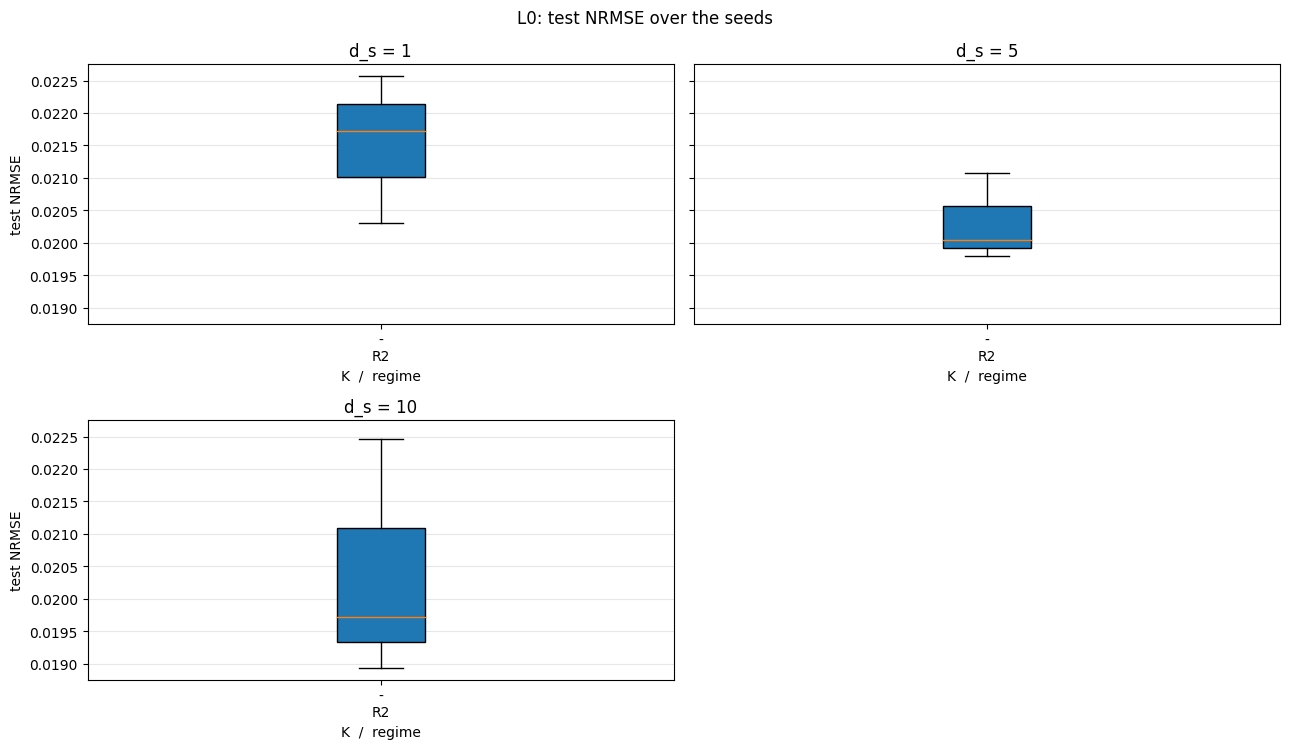

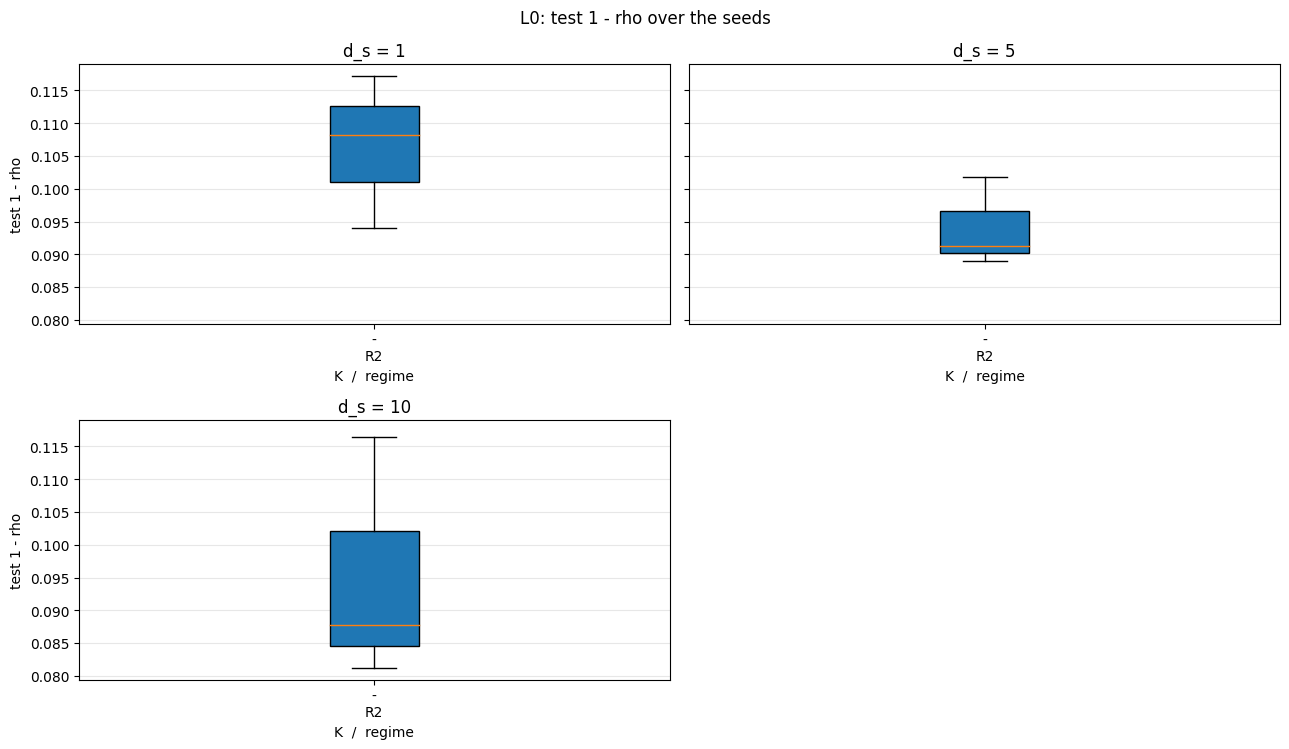

In [59]:
boxplot_variant('L0', 'nrmse_test')
boxplot_variant('L0', 'one_minus_rho_test')

### L0: trend with the dimensionality

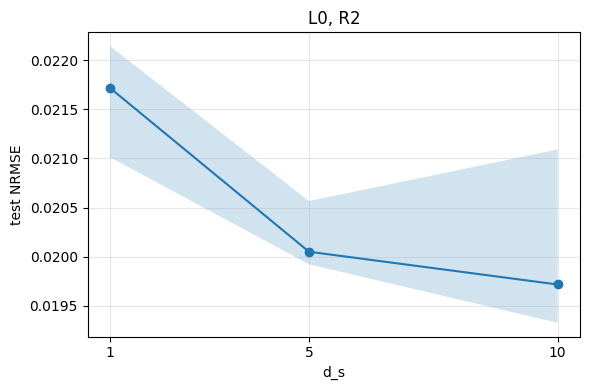

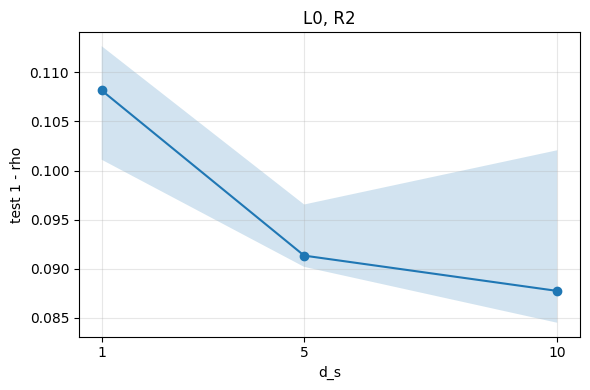

In [60]:
trend_variant('L0', 'nrmse_test')
trend_variant('L0', 'one_minus_rho_test')

## L1: fixed modes, $\bar y+\sum_{k=1}^{d_s}s_k\varphi_k$

The latent states are the coefficients of the first $d_s$ POD modes (`build_L1`, $K=d_s$): the reconstructor has **no trainable parameter**. In R2 only $\mathcal{NN}_{\mathrm{dyn}}$ is trained, which forces the latents to be modal. In R1 the fixed formula is just evaluated on the frozen L0 latents (nothing to fit), so R1 measures whether the latents of L0 are modal on their own.

In [19]:
sweep('L1', K_of = lambda d_s: [d_s])

L1: 18 runs to do, 0 already done
[1/18] L1_R1_ds1_K1_s0          train    0.0 s   test NRMSE 2.935e-02
[2/18] L1_R2_ds1_K1_s0          train   47.9 s   test NRMSE 2.200e-02
[3/18] L1_R1_ds5_K5_s0          train    0.0 s   test NRMSE 5.966e-02
[4/18] L1_R2_ds5_K5_s0          train   38.4 s   test NRMSE 7.919e-03
[5/18] L1_R1_ds10_K10_s0        train    0.0 s   test NRMSE 4.690e-02
[6/18] L1_R2_ds10_K10_s0        train   41.5 s   test NRMSE 1.084e-02
[7/18] L1_R1_ds1_K1_s1          train    0.0 s   test NRMSE 6.017e-02
[8/18] L1_R2_ds1_K1_s1          train   45.8 s   test NRMSE 2.072e-02
[9/18] L1_R1_ds5_K5_s1          train    0.0 s   test NRMSE 4.537e-02
[10/18] L1_R2_ds5_K5_s1          train   40.5 s   test NRMSE 9.156e-03
[11/18] L1_R1_ds10_K10_s1        train    0.0 s   test NRMSE 4.658e-02
[12/18] L1_R2_ds10_K10_s1        train   41.7 s   test NRMSE 9.383e-03
[13/18] L1_R1_ds1_K1_s2          train    0.0 s   test NRMSE 3.663e-02
[14/18] L1_R2_ds1_K1_s2          train   44.0 s   te

### L1: comparison of the configurations

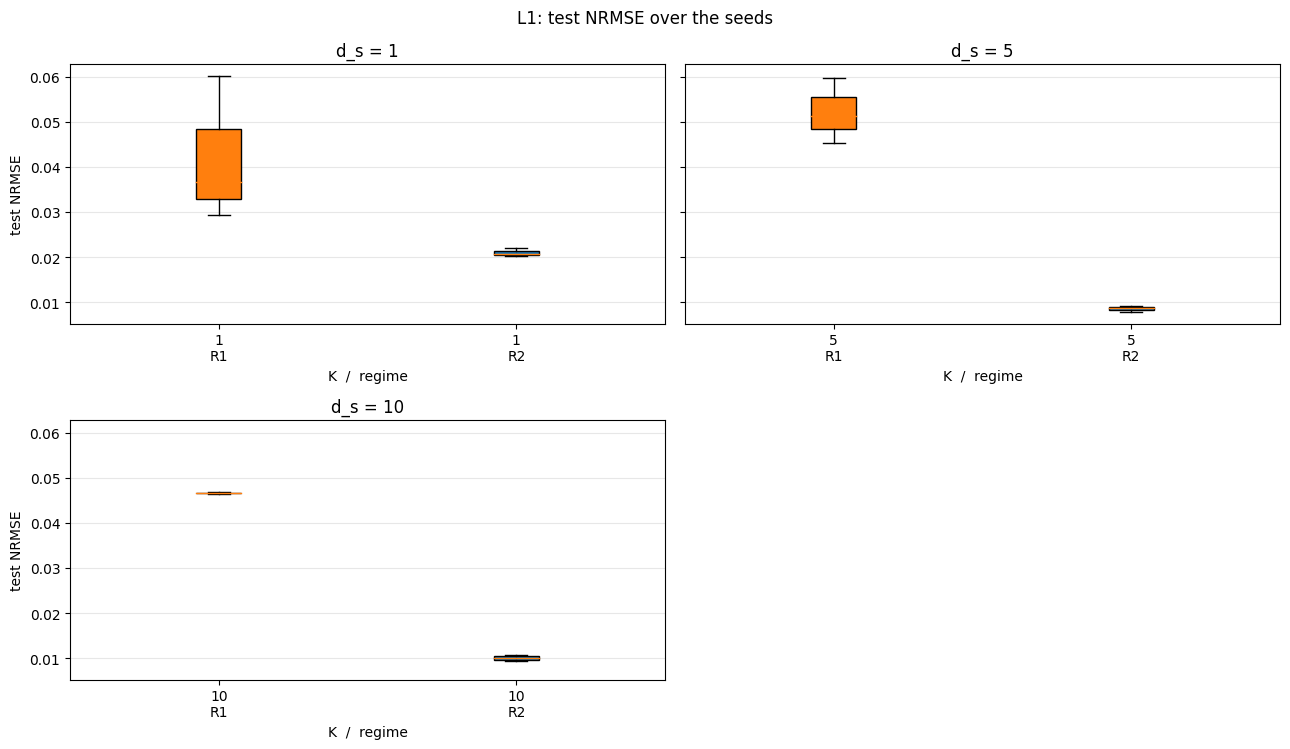

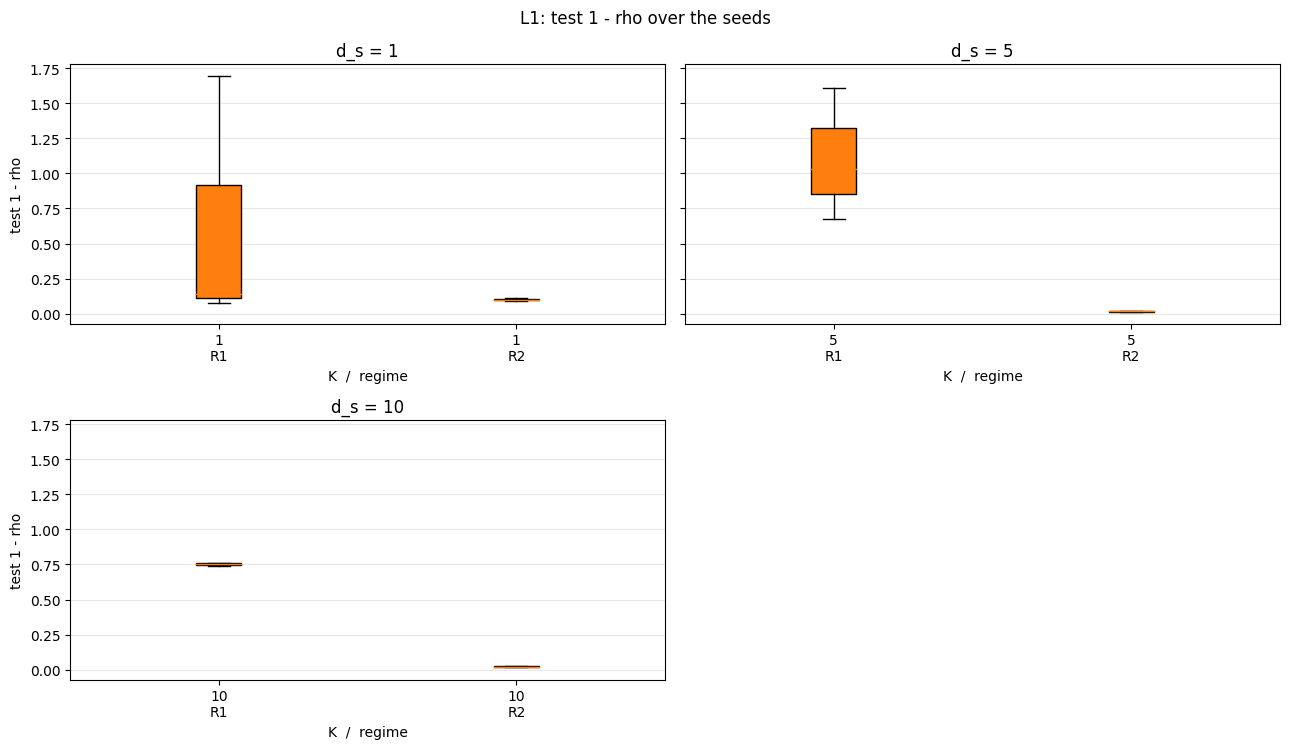

In [61]:
boxplot_variant('L1', 'nrmse_test')
boxplot_variant('L1', 'one_minus_rho_test')

### L1: trend with the dimensionality

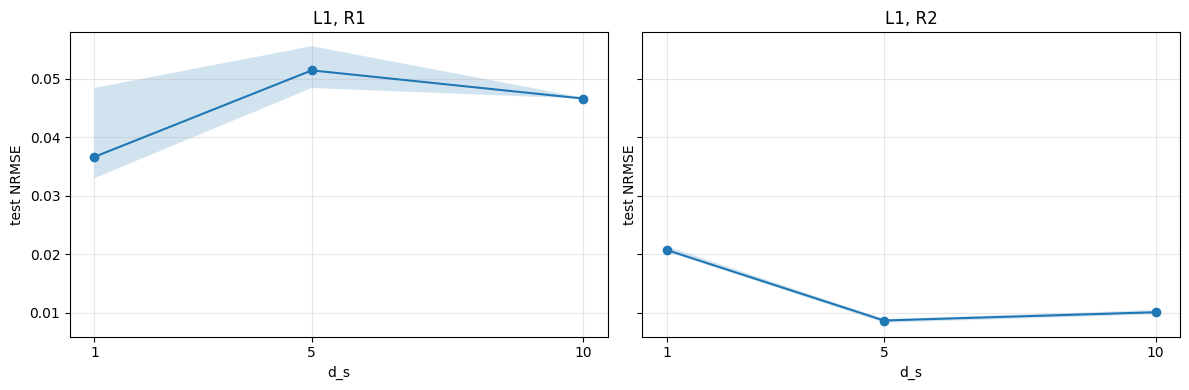

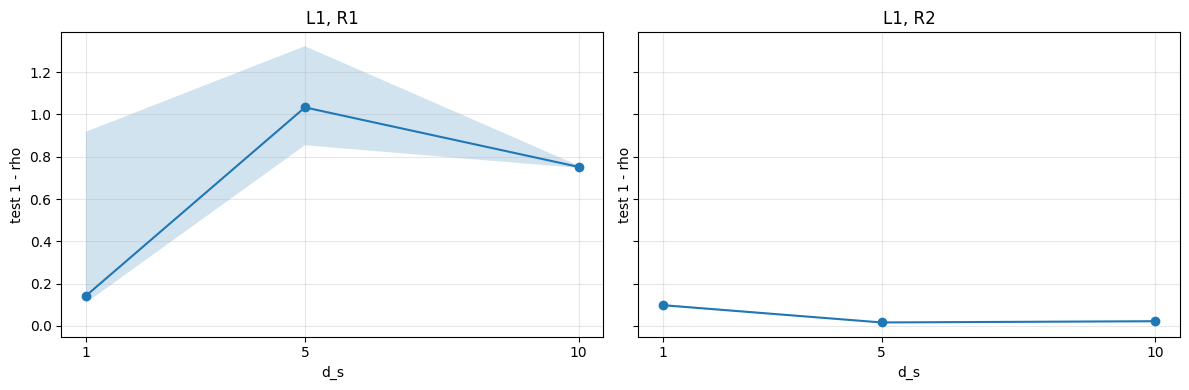

In [62]:
trend_variant('L1', 'nrmse_test')
trend_variant('L1', 'one_minus_rho_test')

## L2: affine map to the modes, $\bar y+\sum_{k=1}^{K}(W\mathbf{z}+\mathbf{b})_k\varphi_k$

The reconstructor (`build_L2`) is linear in $\mathbf{z} = [\mathbf{s}; u]$ with trainable $W\in\mathbb{R}^{K\times (d_s+1)}$ and $\mathbf{b}\in\mathbb{R}^K$ ($K(d_s+2)$ parameters), on the fixed POD basis without the tail compression. The sweep is over $d_s$ and $K$.

In [22]:
sweep('L2')

L2: 84 runs to do, 0 already done
[1/84] L2_R1_ds1_K1_s0          train   10.5 s   test NRMSE 1.970e-02
[2/84] L2_R2_ds1_K1_s0          train   41.1 s   test NRMSE 2.497e-02
[3/84] L2_R1_ds1_K3_s0          train   10.8 s   test NRMSE 1.821e-02
[4/84] L2_R2_ds1_K3_s0          train   39.8 s   test NRMSE 1.938e-02
[5/84] L2_R1_ds1_K5_s0          train   12.9 s   test NRMSE 1.823e-02
[6/84] L2_R2_ds1_K5_s0          train   38.8 s   test NRMSE 1.503e-02
[7/84] L2_R1_ds1_K9_s0          train   17.8 s   test NRMSE 1.896e-02
[8/84] L2_R2_ds1_K9_s0          train   40.6 s   test NRMSE 1.475e-02
[9/84] L2_R1_ds1_K17_s0         train   23.4 s   test NRMSE 1.901e-02
[10/84] L2_R2_ds1_K17_s0         train   45.5 s   test NRMSE 1.636e-02
[11/84] L2_R1_ds5_K3_s0          train   28.4 s   test NRMSE 1.736e-02
[12/84] L2_R2_ds5_K3_s0          train   38.6 s   test NRMSE 9.609e-03
[13/84] L2_R1_ds5_K5_s0          train   29.4 s   test NRMSE 1.557e-02
[14/84] L2_R2_ds5_K5_s0          train   39.6 s   te

### L2: comparison of the configurations

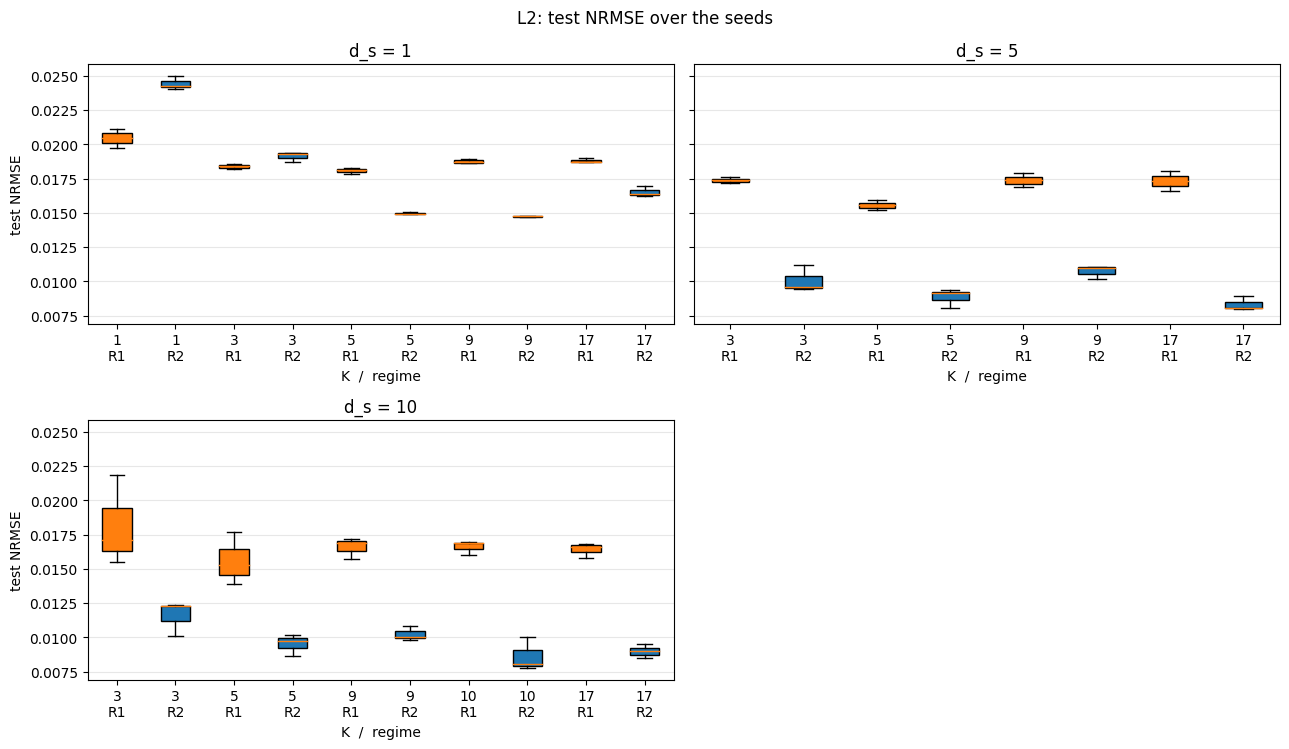

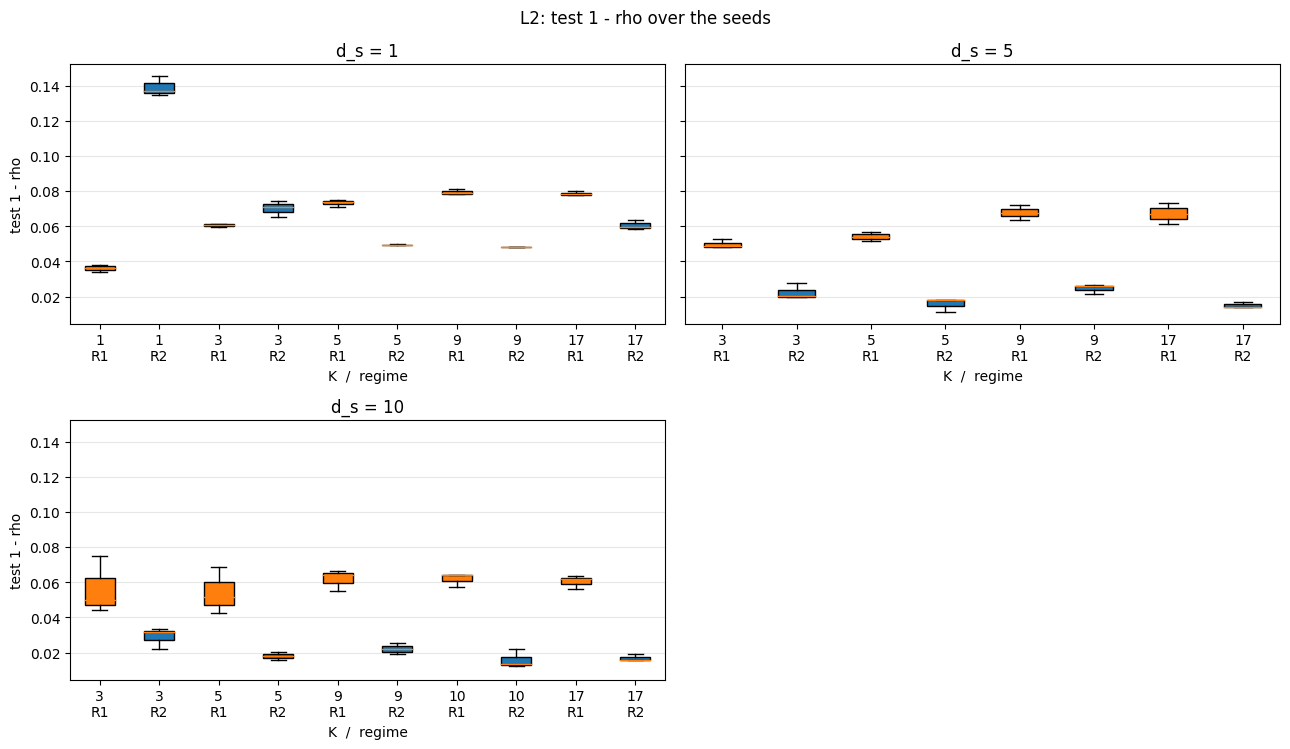

In [63]:
boxplot_variant('L2', 'nrmse_test')
boxplot_variant('L2', 'one_minus_rho_test')

### L2: trend with the dimensionality

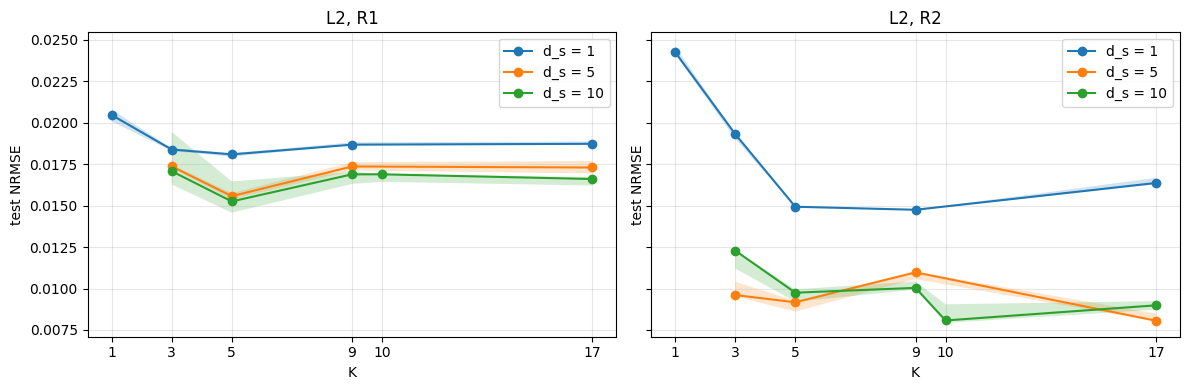

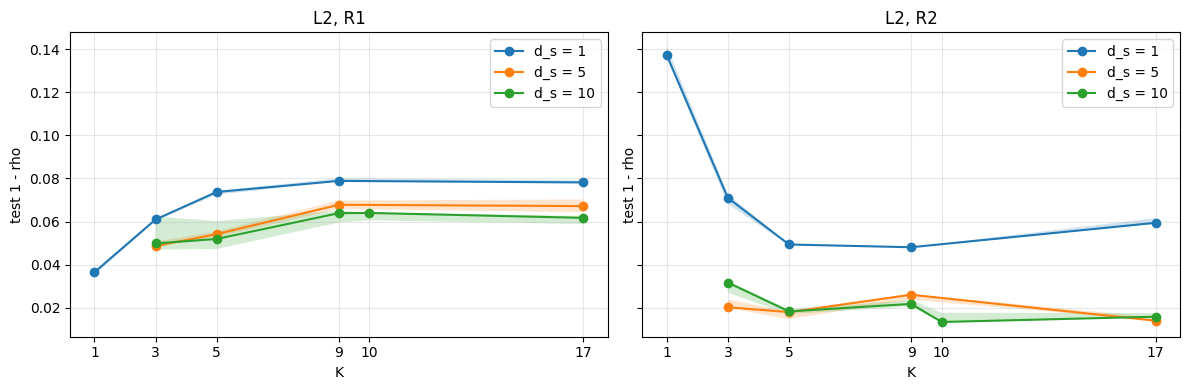

In [64]:
trend_variant('L2', 'nrmse_test')
trend_variant('L2', 'one_minus_rho_test')

## L3: nonlinear map to the modes, $\bar y+\sum_{k=1}^{K}g_\theta(\mathbf{z})_k\varphi_k$

$g_\theta:\mathbb{R}^{d_s+1}\to\mathbb{R}^K$ (`build_L3`) is a tanh MLP with two hidden layers whose width is the largest one with at most as many parameters as the L0 reconstructor (minimum 1), on the fixed POD basis without the tail compression.

**Caution when reading the trend with $K$:** the budget fixes the width, so it shrinks as $K$ grows (see `width` and `rec_params` in `runs.csv`). The large-$K$ points therefore mostly measure a bottleneck of the MLP, not of the basis; a best-size sweep (protocol Sec. 4) is the natural follow-up.

In [25]:
sweep('L3')

L3: 84 runs to do, 0 already done
[1/84] L3_R1_ds1_K1_s0          train   73.5 s   test NRMSE 1.899e-02
[2/84] L3_R2_ds1_K1_s0          train   83.6 s   test NRMSE 1.882e-02
[3/84] L3_R1_ds1_K3_s0          train   74.5 s   test NRMSE 8.558e-03
[4/84] L3_R2_ds1_K3_s0          train   81.4 s   test NRMSE 9.229e-03
[5/84] L3_R1_ds1_K5_s0          train   79.4 s   test NRMSE 5.501e-03
[6/84] L3_R2_ds1_K5_s0          train   85.9 s   test NRMSE 6.259e-03
[7/84] L3_R1_ds1_K9_s0          train   79.3 s   test NRMSE 4.556e-03
[8/84] L3_R2_ds1_K9_s0          train   86.1 s   test NRMSE 5.379e-03
[9/84] L3_R1_ds1_K17_s0         train   79.7 s   test NRMSE 4.372e-03
[10/84] L3_R2_ds1_K17_s0         train   87.6 s   test NRMSE 5.212e-03
[11/84] L3_R1_ds5_K3_s0          train   85.5 s   test NRMSE 8.942e-03
[12/84] L3_R2_ds5_K3_s0          train   94.4 s   test NRMSE 9.804e-03
[13/84] L3_R1_ds5_K5_s0          train   81.6 s   test NRMSE 5.809e-03
[14/84] L3_R2_ds5_K5_s0          train   94.7 s   te

### L3: comparison of the configurations

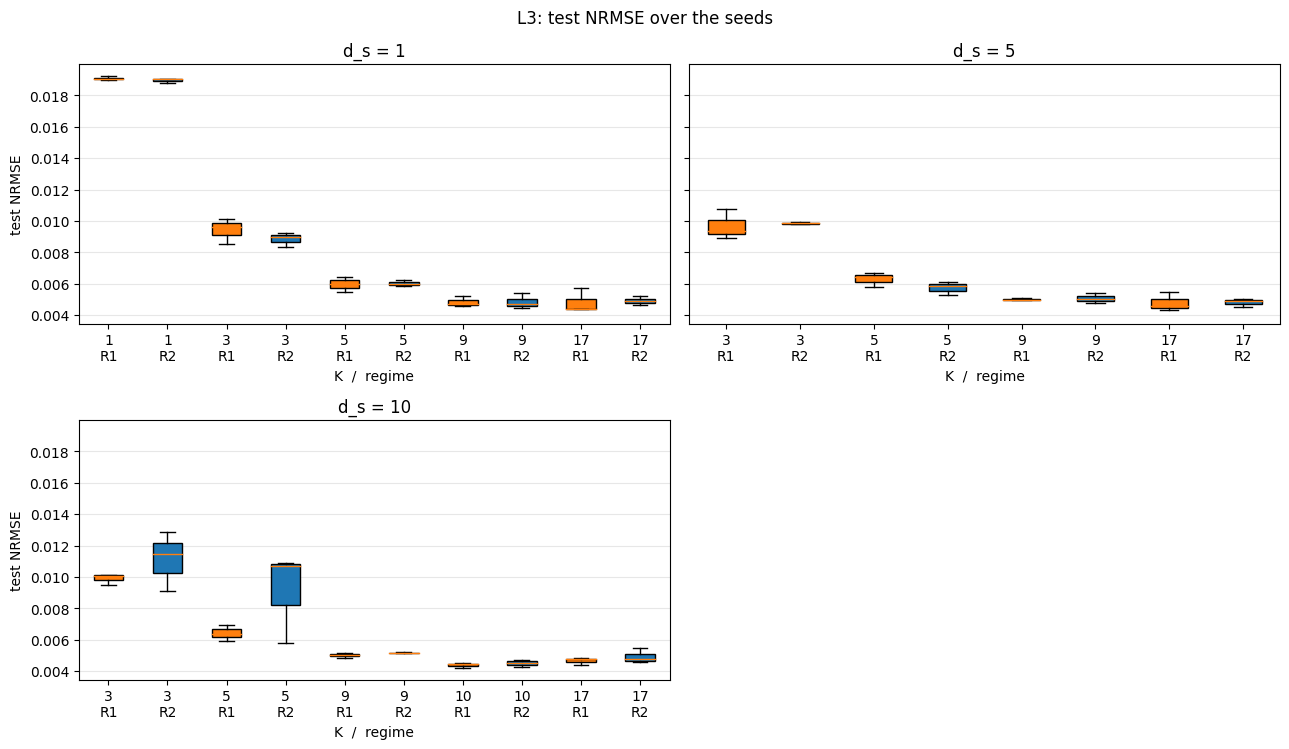

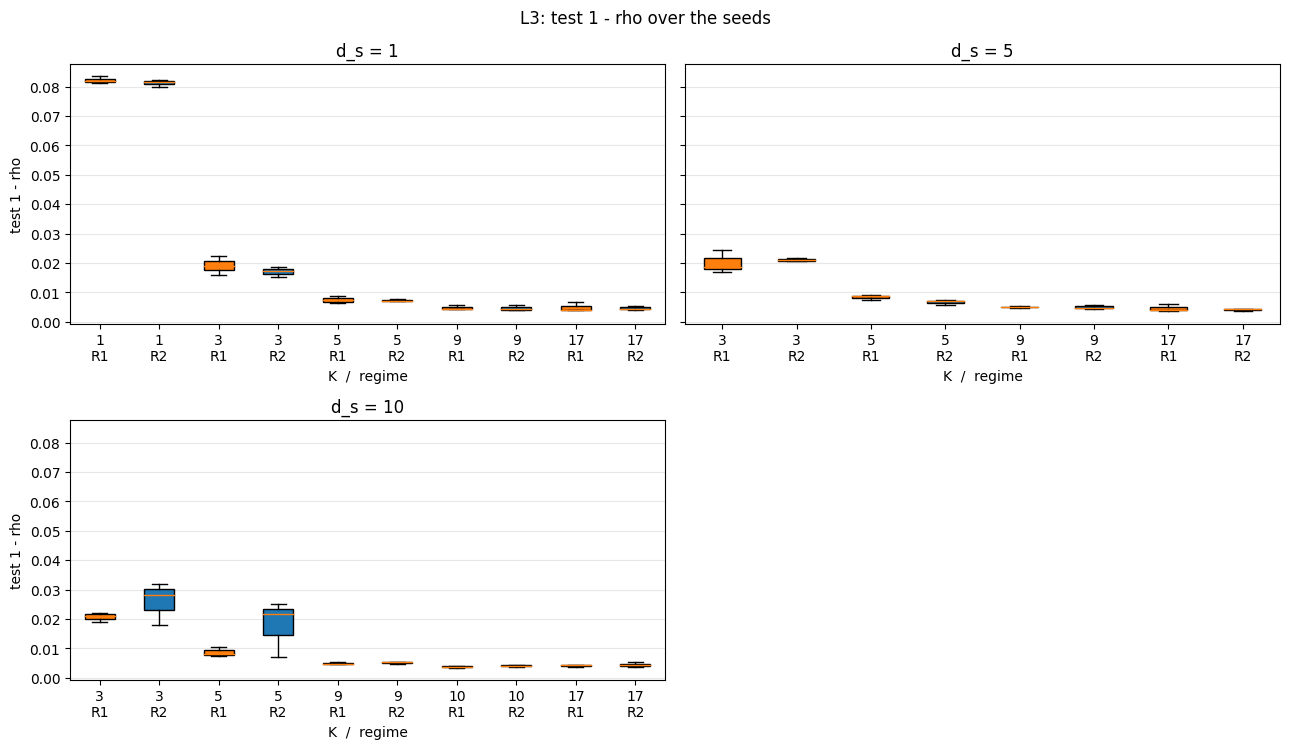

In [65]:
boxplot_variant('L3', 'nrmse_test')
boxplot_variant('L3', 'one_minus_rho_test')

### L3: trend with the dimensionality

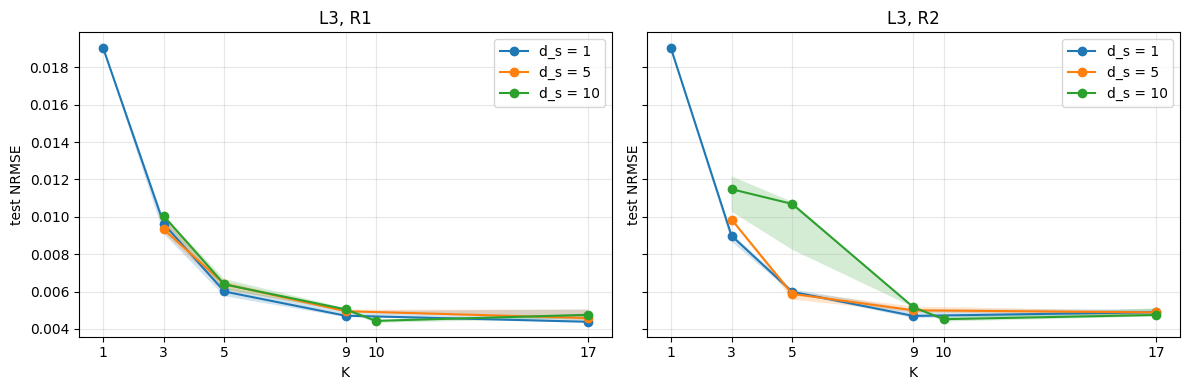

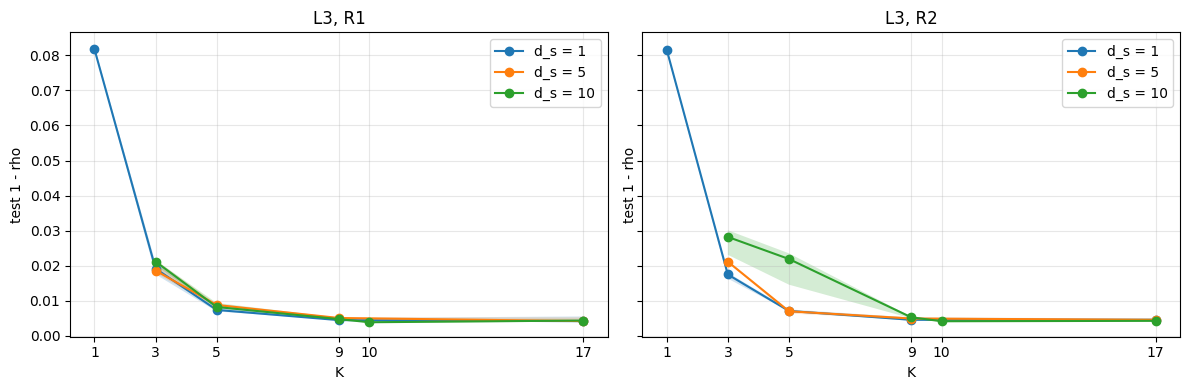

In [66]:
trend_variant('L3', 'nrmse_test')
trend_variant('L3', 'one_minus_rho_test')

## Final comparison: the best configuration of every procedure

A procedure is a variant with a regime (L0 appears once). Its **best configuration** is the $(d_s,K)$ with the lowest median validation NRMSE over the seeds: the test set is never used to choose (pass `select = 'nrmse_test'` to `best_configs` to choose on it instead). The table shows the medians over the seeds, then a boxplot over the seeds compares the procedures.

In [28]:
CONFIG = ['variant', 'regime', 'd_s', 'K']

def best_configs(select = 'nrmse_valid'):
    '''For every (variant, regime): the (d_s, K) with the lowest median `select` over the seeds.'''
    med = load('runs').groupby(CONFIG)[select].median().reset_index()
    return med.loc[med.groupby(['variant', 'regime'])[select].idxmin(), CONFIG]

best = best_configs()
best_runs = load('runs').merge(best, on = CONFIG)                           # all the seeds of the best configurations

columns = ['rec_params', 'nrmse_train', 'nrmse_test', 'one_minus_rho_train', 'one_minus_rho_test',
           'eps_total_test', 'eps_proj_test', 'eff_ratio_test',
           'dir_test', 'vort_rel_test', 'extrap_ratio_test', 'train_time_s', 'infer_time_s']
table = best_runs.groupby(CONFIG)[columns].median().reset_index()
table['rec_params'] = table['rec_params'].astype(int)
print(table.to_string(index = False, float_format = lambda v: '%1.3e' % v))

variant regime  d_s  K  rec_params  nrmse_train  nrmse_test  one_minus_rho_train  one_minus_rho_test  eps_total_test  eps_proj_test  eff_ratio_test  dir_test  vort_rel_test  extrap_ratio_test  train_time_s  infer_time_s
     L0     R2   10  0        2186    1.267e-02   1.972e-02            8.614e-02           8.774e-02       4.111e-01            NaN             NaN 5.112e-02      8.865e-01          9.740e-01     2.400e+02     9.319e-01
     L1     R1    1  1           0    2.410e-02   3.663e-02            1.735e-01           1.423e-01       7.637e-01      2.215e-01       3.448e+00 3.230e-01      7.645e-01          9.795e-01     0.000e+00     1.226e-02
     L1     R2    5  5           0    6.070e-03   8.688e-03            1.868e-02           1.653e-02       1.811e-01      5.092e-02       3.557e+00 4.774e-02      2.412e-01          9.677e-01     3.836e+01     7.971e-03
     L2     R1   10  5          60    9.498e-03   1.525e-02            4.766e-02           5.191e-02       3.180e-01    

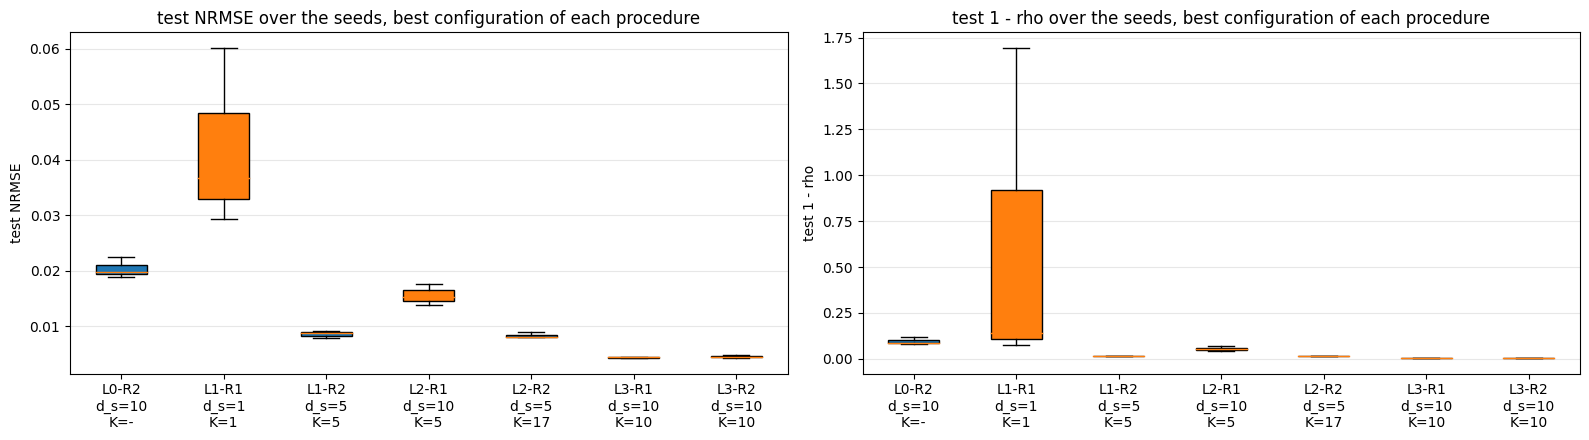

In [67]:
fig, axs = plt.subplots(1, 2, figsize = (16, 4.5))
groups = list(best_runs.groupby(CONFIG))
for ax, metric in zip(axs, ['nrmse_test', 'one_minus_rho_test']):
    bp = ax.boxplot([g[metric].values for _, g in groups], patch_artist = True,
                    labels = [f"{v}-{r}\nd_s={d}\nK={K if K else '-'}" for (v, r, d, K), _ in groups])
    for patch, ((v, r, d, K), _) in zip(bp['boxes'], groups):
        patch.set_facecolor(REGIME_COLOR[r])
    ax.set(ylabel = LABEL[metric], yscale = 'linear', title = f'{LABEL[metric]} over the seeds, best configuration of each procedure')
    ax.grid(True, axis = 'y', alpha = 0.3)
fig.tight_layout()
plt.show()

### Predictions compared to the FOM

For every procedure, the seed with the lowest validation NRMSE of its best configuration, rebuilt from the saved weights (the check verifies that the rebuilt model gives the stored test NRMSE). FOM on the top rows, reduced model below, as in the original script (test sample 0).

L0-R2: d_s = 10, K = -, seed 1, test NRMSE 1.894e-02


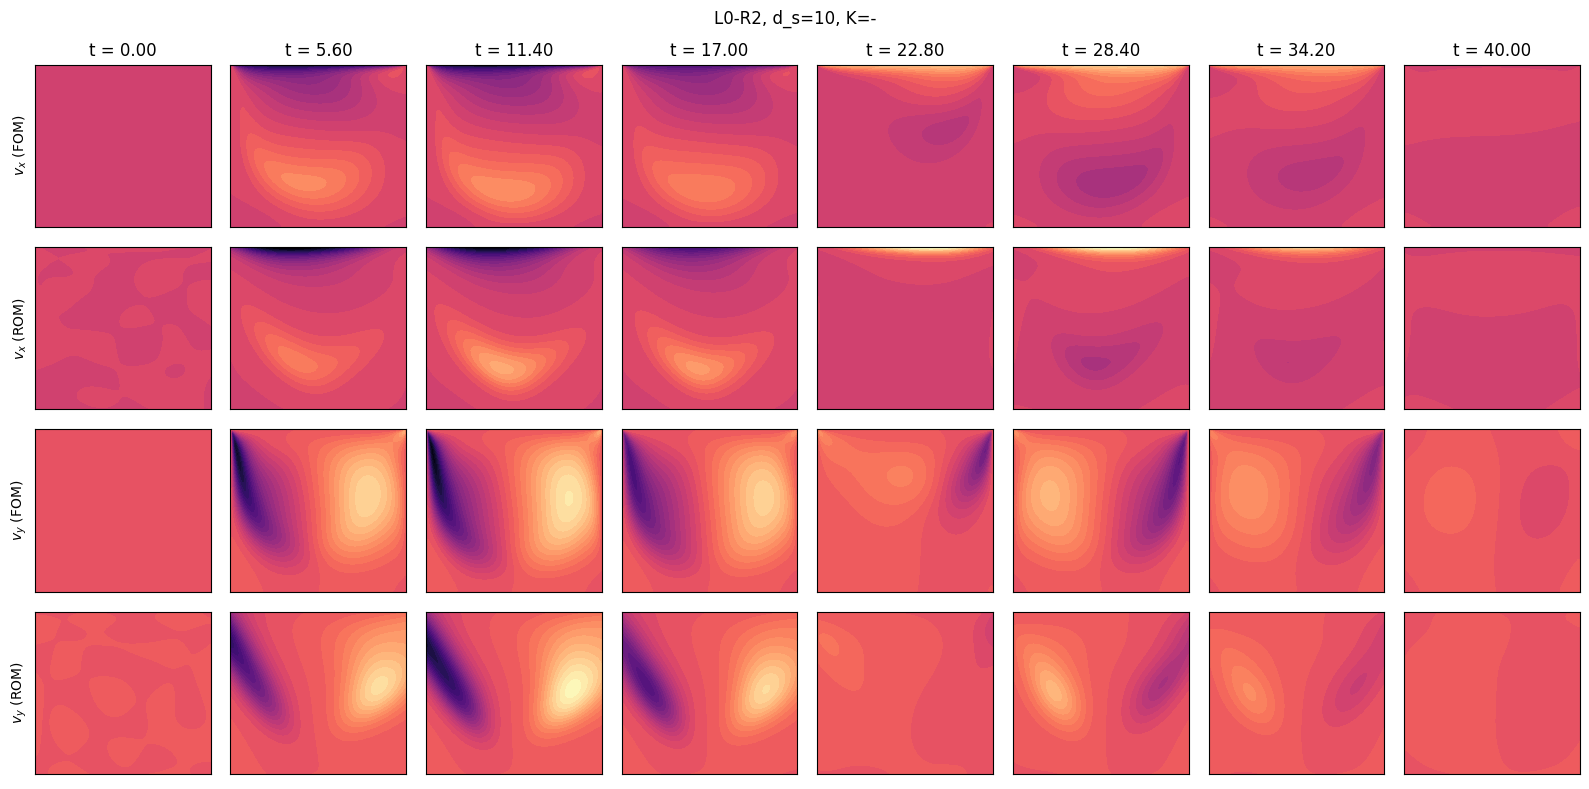

L1-R1: d_s = 1, K = 1, seed 0, test NRMSE 2.935e-02


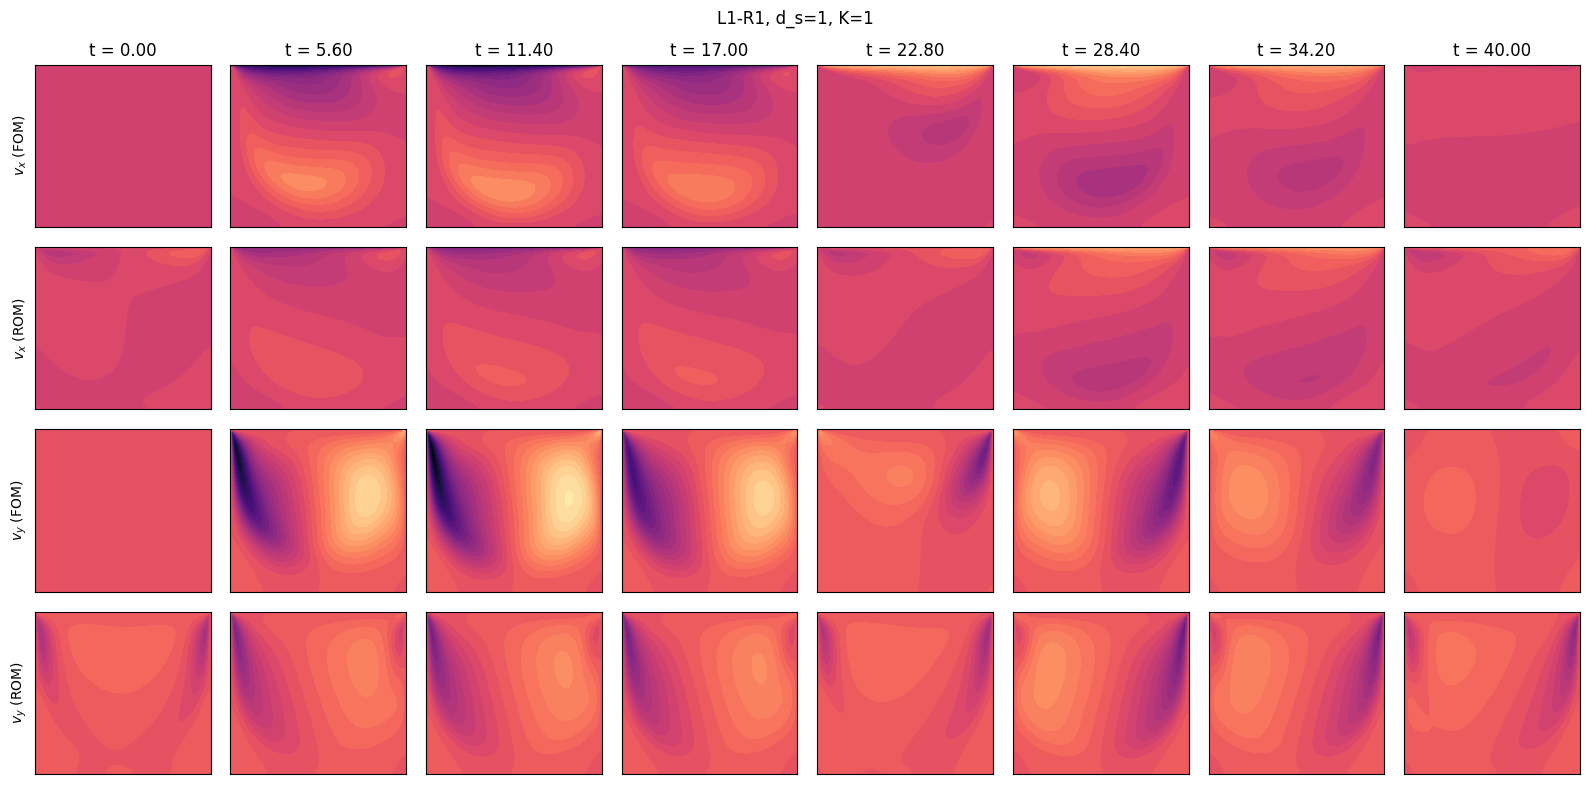

L1-R2: d_s = 5, K = 5, seed 0, test NRMSE 7.919e-03


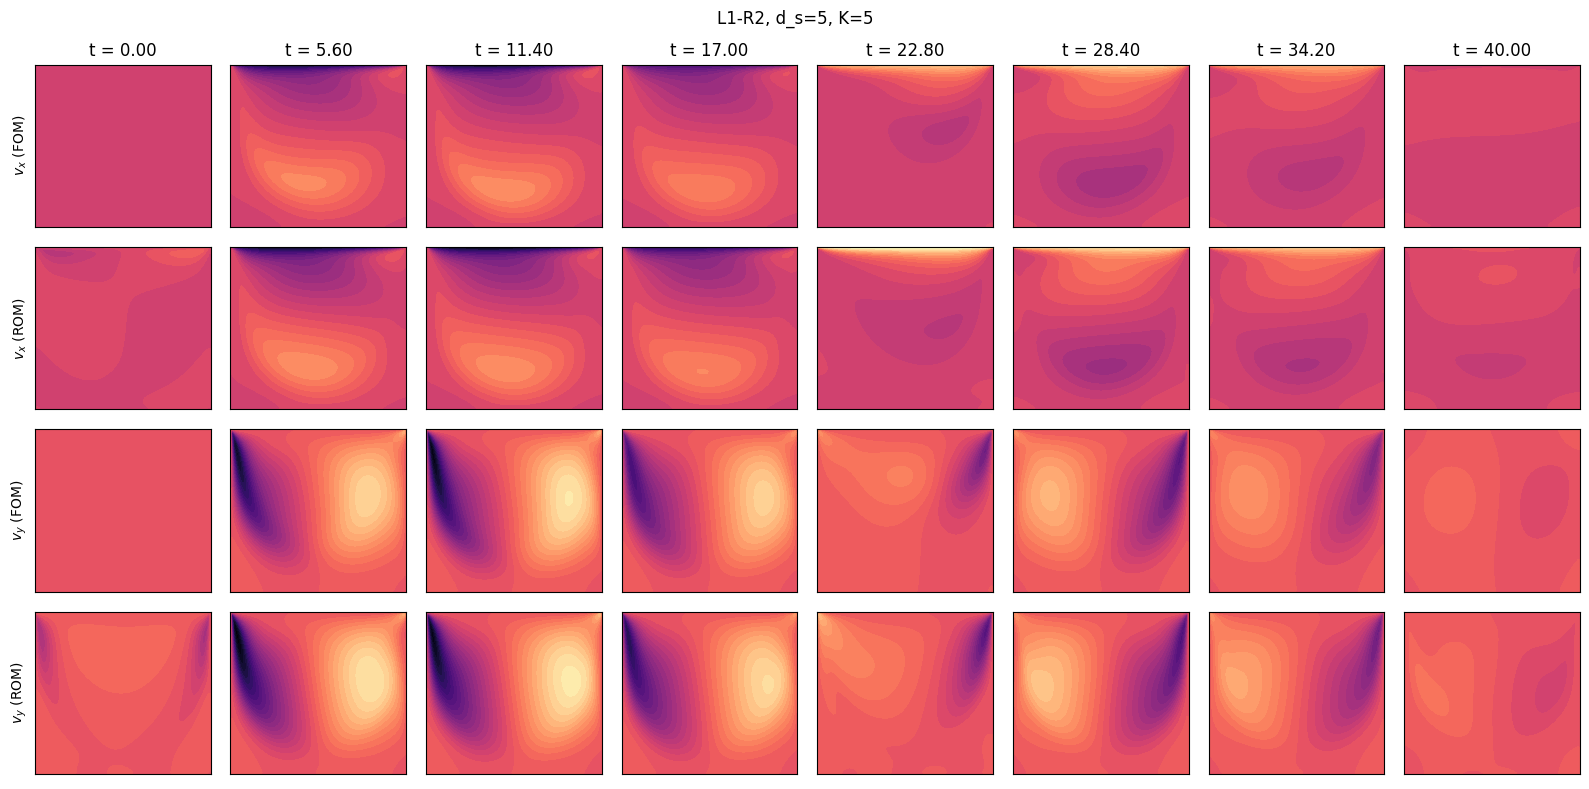

L2-R1: d_s = 10, K = 5, seed 0, test NRMSE 1.389e-02


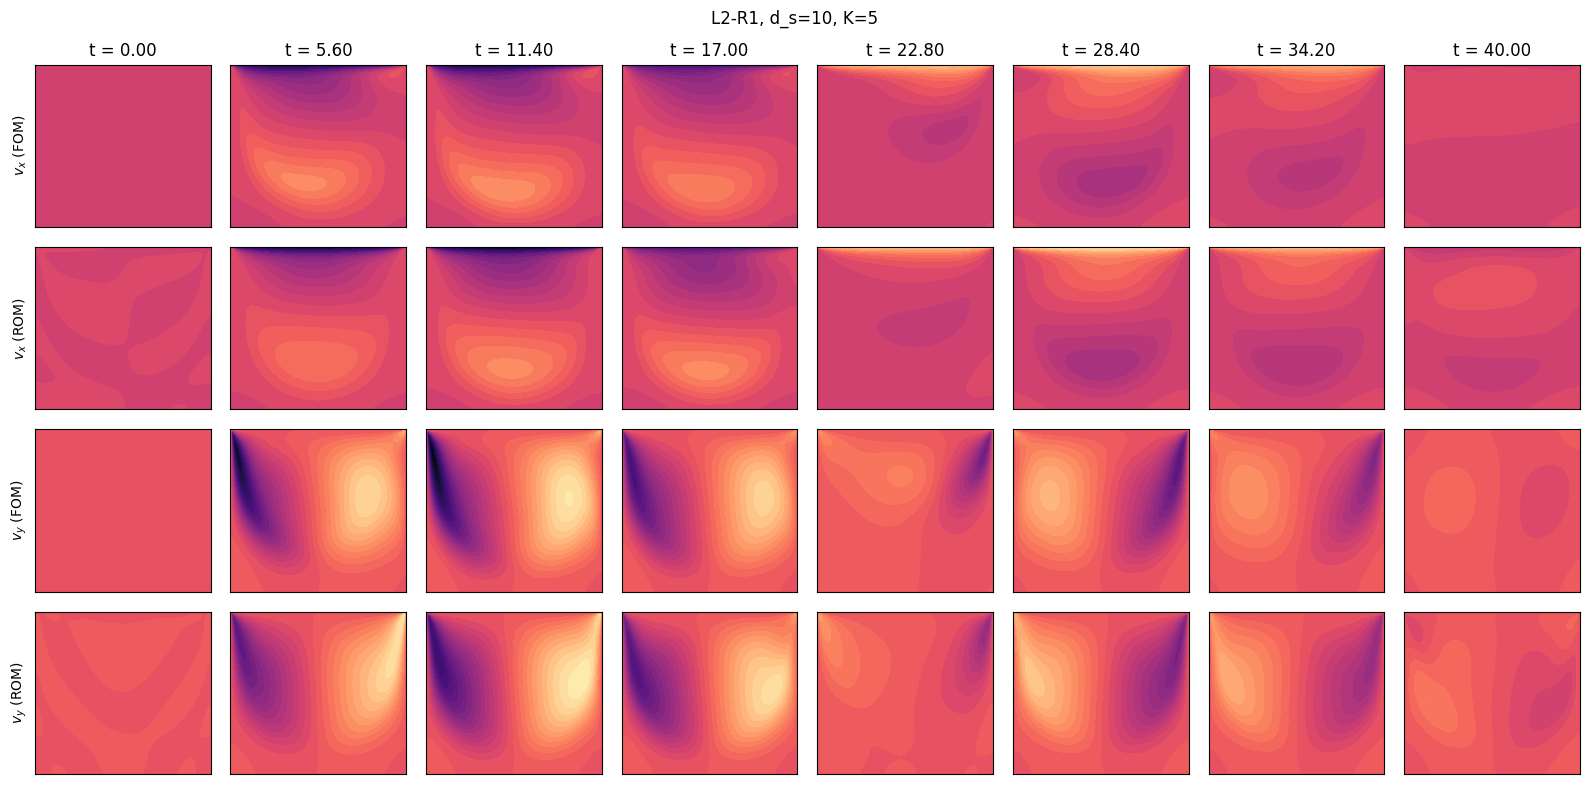

L2-R2: d_s = 5, K = 17, seed 2, test NRMSE 7.983e-03


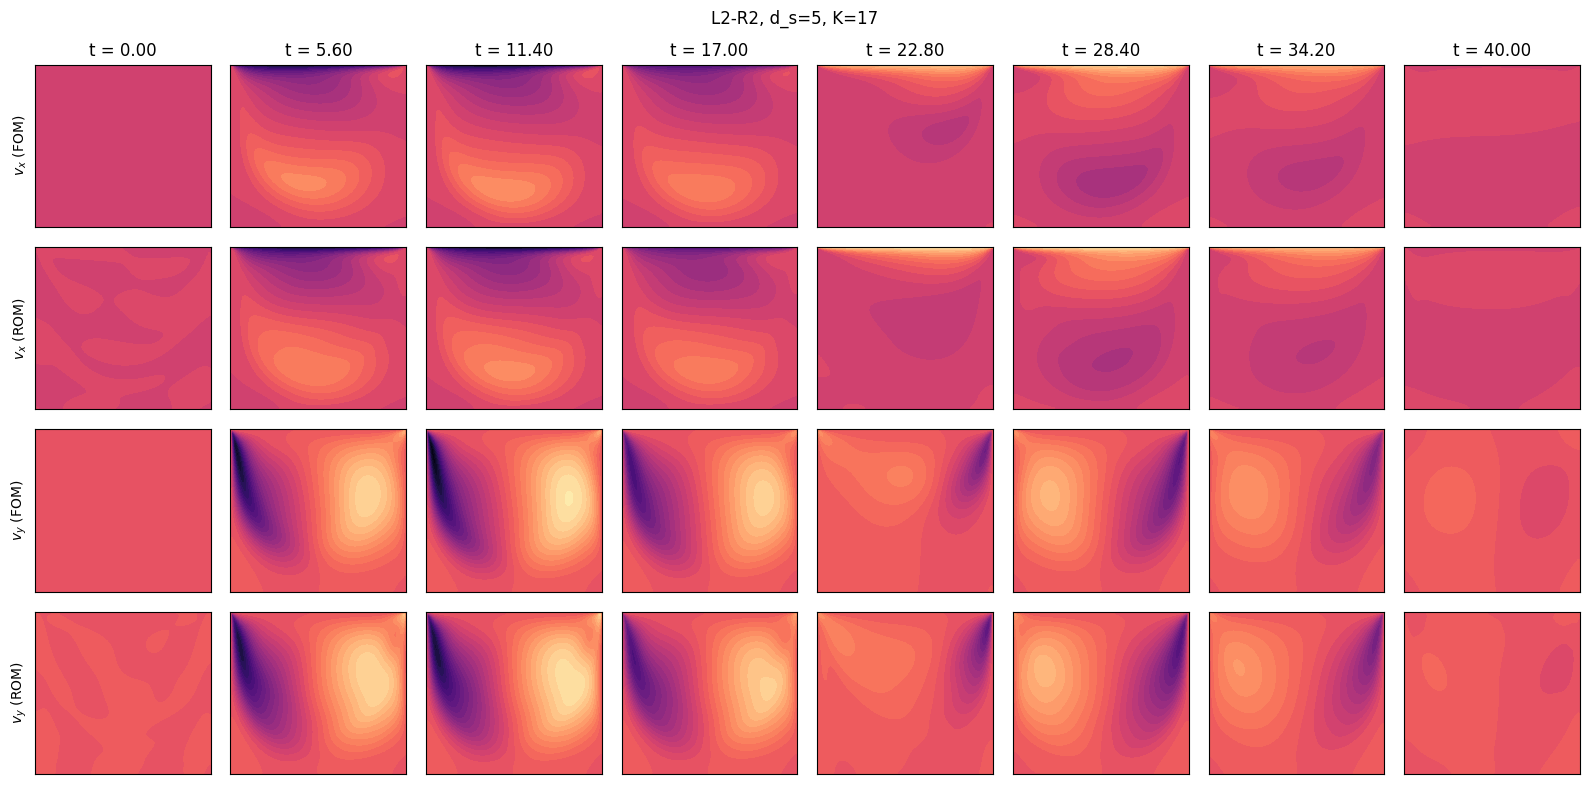

L3-R1: d_s = 10, K = 10, seed 0, test NRMSE 4.212e-03


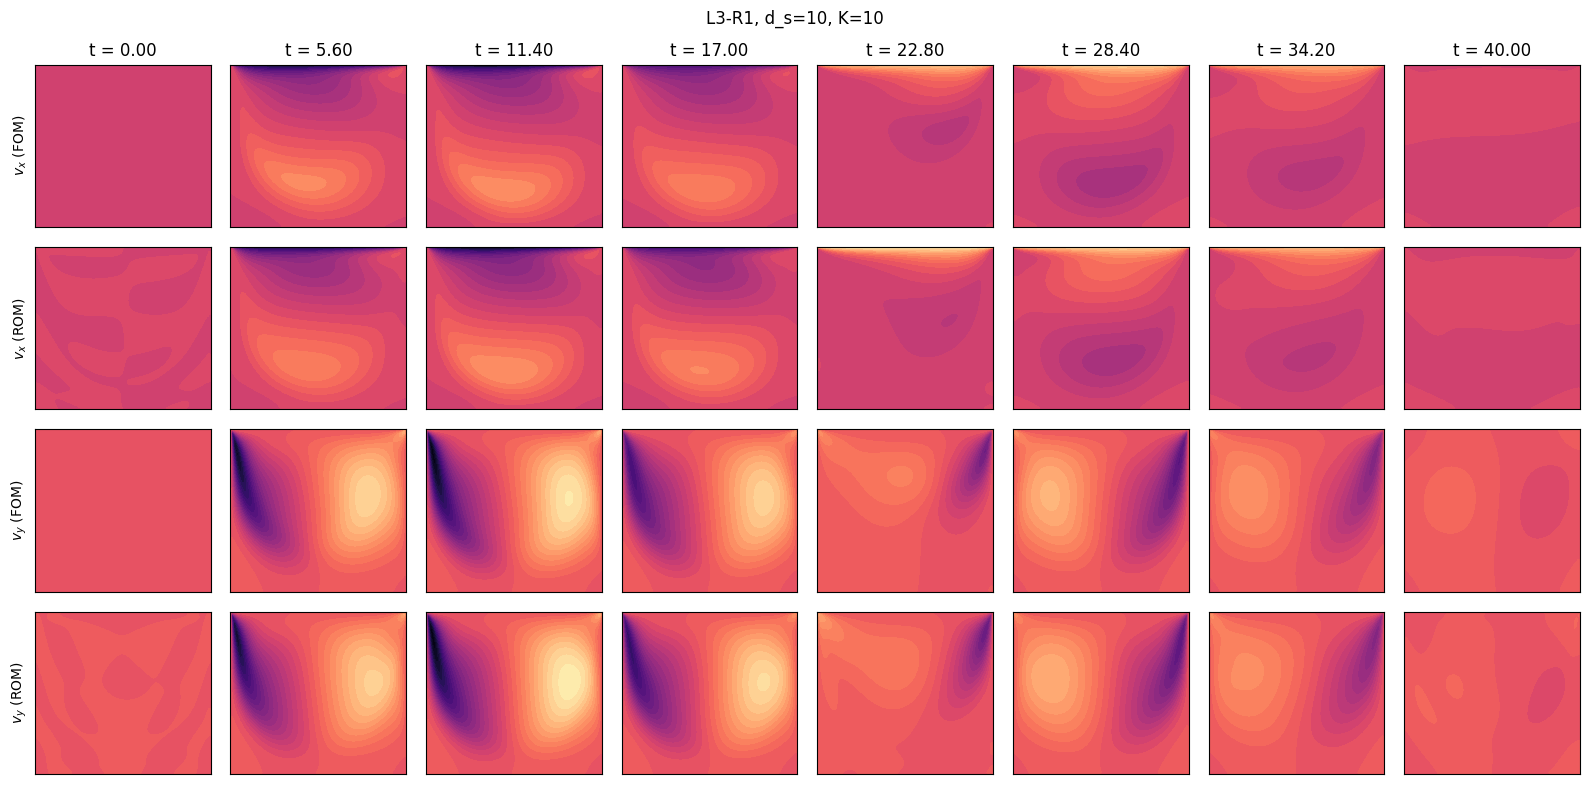

L3-R2: d_s = 10, K = 10, seed 1, test NRMSE 4.267e-03


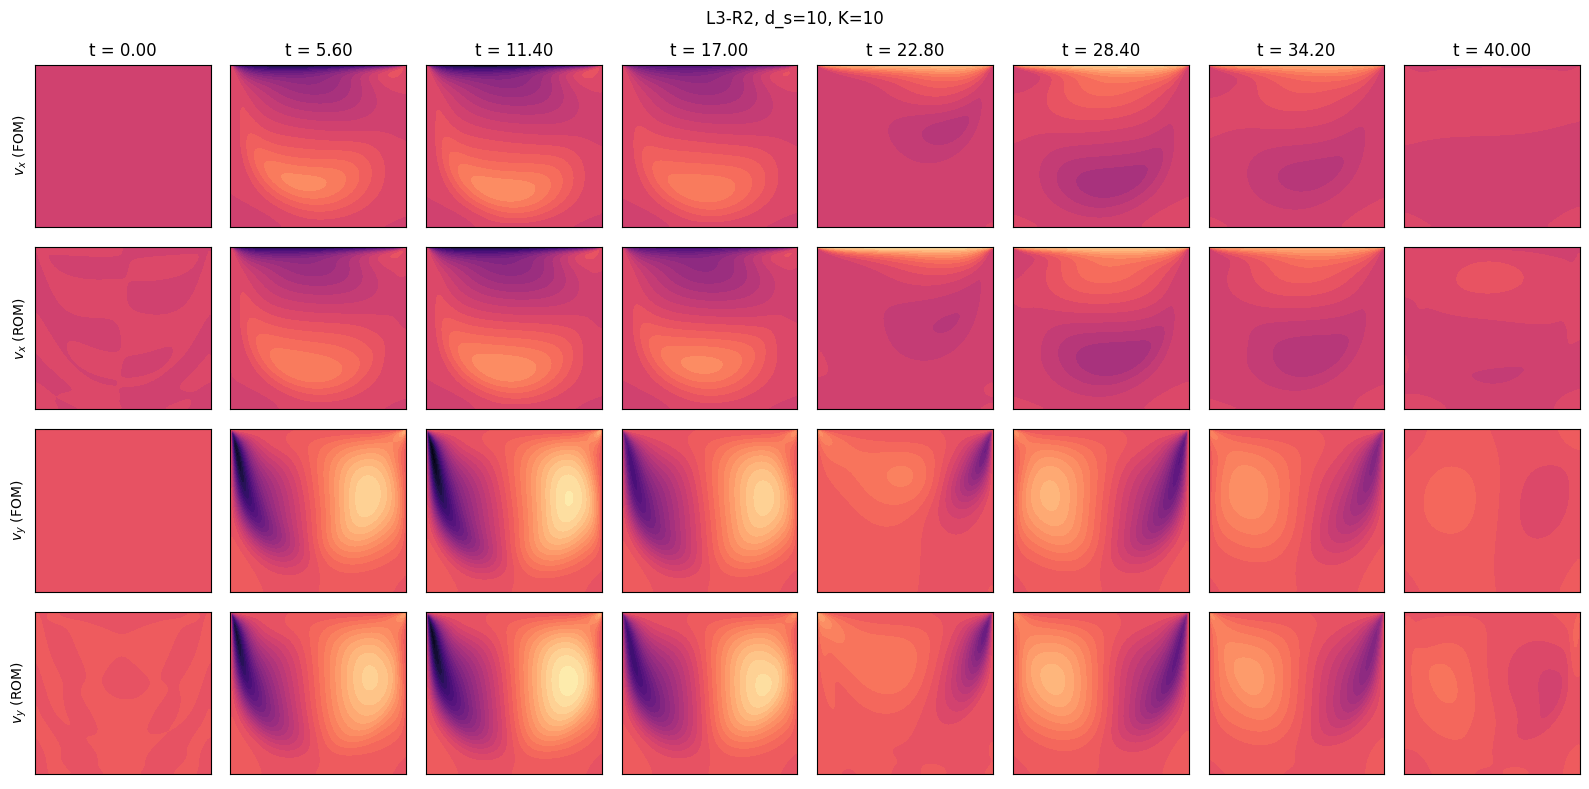

In [30]:
for (variant, regime, d_s, K), g in best_runs.groupby(CONFIG):
    best_run = g.loc[g.nrmse_valid.idxmin()]
    pred = predict_test(variant, regime, d_s, K, int(best_run.seed))
    print(f'{variant}-{regime}: d_s = {d_s}, K = {K if K else "-"}, seed {int(best_run.seed)}, test NRMSE {best_run.nrmse_test:.3e}')
    assert np.isclose(nrmse_rho(pred, REF['test'])[0], best_run.nrmse_test, rtol = 1e-6), 'rebuilt model does not match the stored result'
    plot_fom_contours(REF['test'], pred, title_ROM = f'{variant}-{regime}, d_s={d_s}, K={K if K else "-"}')
    plt.show()